In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [3]:
clusters_c2_ni20_maxi500_h2 = pd.read_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_h2.parquet')

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [4]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_index_winsorized.parquet')

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [5]:
import random

In [6]:
def estimate_hpi_by_cluster_sampling(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster that are present in the HPI DataFrame
    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]
    
    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data to perform exclusion and sampling.")
    
    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Print available HPI values for sampling
        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histogram with confidence interval
        axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
        axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
        axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
        axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
        axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
        axes[0].set_xlabel("Sample Mean HPI")
        axes[0].set_ylabel("Frequency")
        axes[0].legend()
        axes[0].grid(True)

        # Convergence plot
        axes[1].plot(cumulative_means, color='purple')
        axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
        axes[1].set_title("Mean Convergence Over Iterations")
        axes[1].set_xlabel("Iteration")
        axes[1].set_ylabel("Cumulative Mean")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

### Sampling experiment with seed 52

🔍 Cluster 0 selected. Excluding country: Germany
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Chile', 'Colombia', 'Czech Republic', 'Denmark', 'France', 'Hungary', 'Iceland', 'India', 'Japan', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Russia', 'Serbia', 'South Africa', 'South Korea', 'Sweden', 'Thailand', 'Turkey', 'United Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


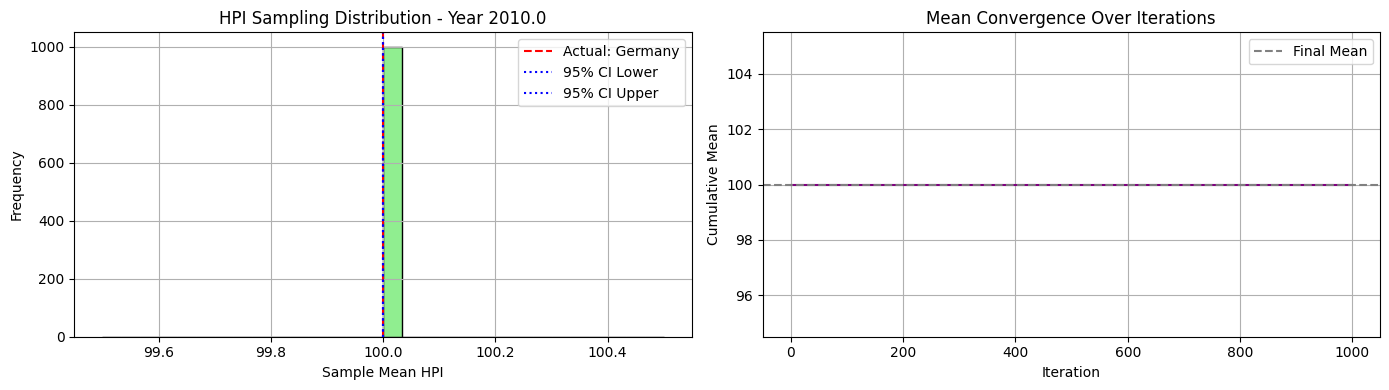


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 105.75 110.52 107.89 100.02  98.29 105.69  96.56 105.5
 110.52 100.07 105.8  108.01 105.57 100.08  94.49  97.62 103.59 105.23
 102.58 104.26 108.8   98.54  97.24]


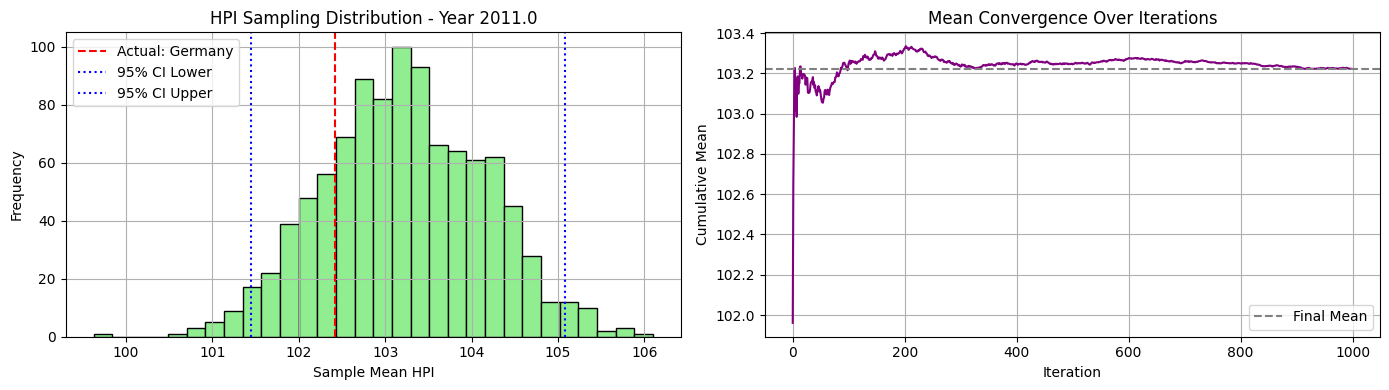


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 110.62 124.02 118.79  98.56  95.67 105.11  92.98 112.38
 124.02  99.19 109.17 115.34 114.94  96.58  91.1   95.68 108.41 108.25
 103.86 107.63 120.68  98.92 101.82]


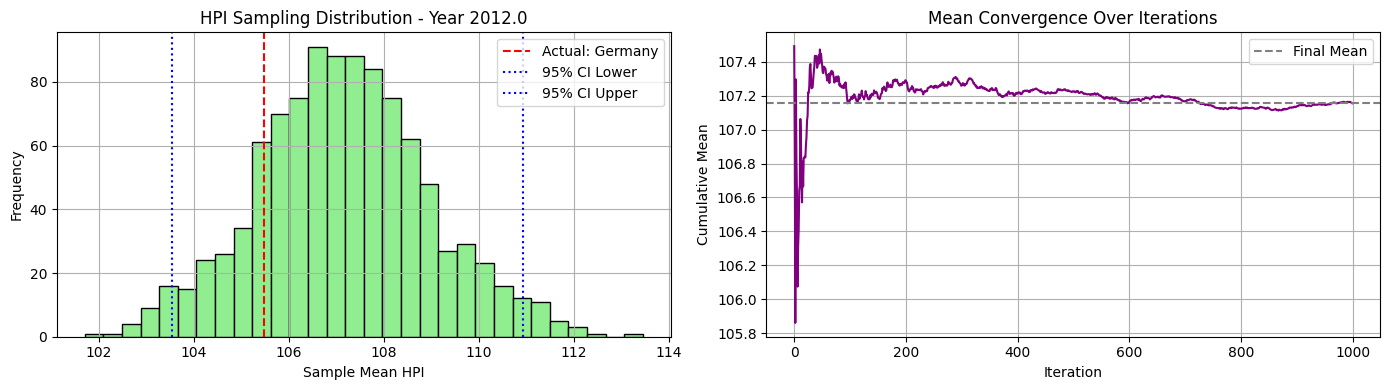


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 112.76 136.52 130.06  98.58  99.37 103.13  90.58 119.18
 136.52 100.81 114.75 119.98 127.86  92.35  94.32  90.62 115.41 107.8
 109.22 115.99 134.46 101.46 111.83]


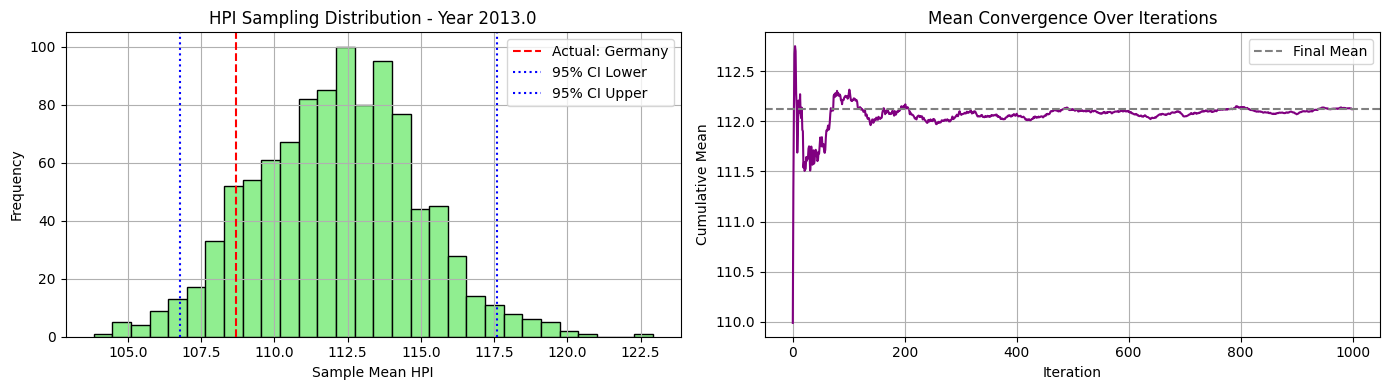


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 118.86 151.67 140.75 101.   103.12 101.58  94.37 128.94
 151.67 102.38 119.64 123.24 142.76  93.27  95.84  95.77 123.99 109.43
 119.52 127.07 151.25 109.6  118.88]


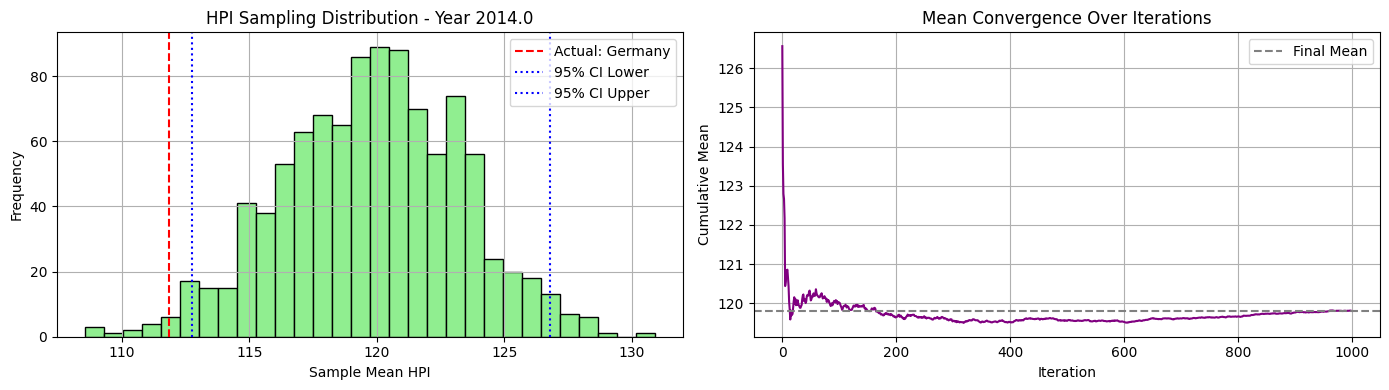


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 128.43 162.89 152.93 105.01 110.29 100.22 106.75 139.74
 162.89 104.86 129.39 130.76 157.04  94.69  97.    99.5  131.8  113.08
 135.2  136.   162.89 116.12 125.18]


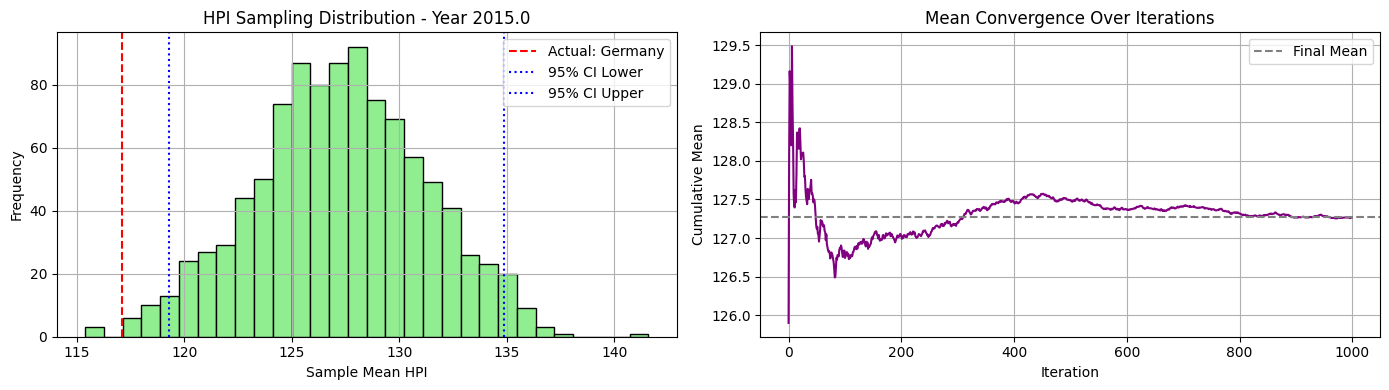


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 148.66 172.75 167.48 112.52 115.5  101.25 121.03 154.59
 172.75 107.18 138.82 139.95 172.75  96.44  91.86 110.62 138.22 116.09
 146.34 142.4  172.75 124.27 131.88]


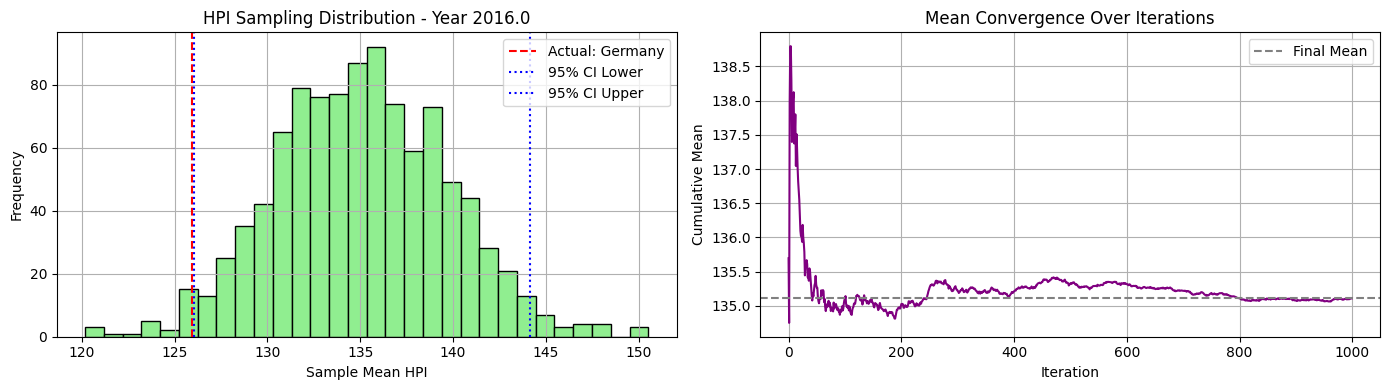


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 172.3  183.99 178.56 125.7  120.63 104.46 135.84 183.99
 183.99 109.91 149.69 146.91 178.82 100.16  88.54 115.3  143.94 117.6
 156.06 146.48 183.99 129.93 139.61]


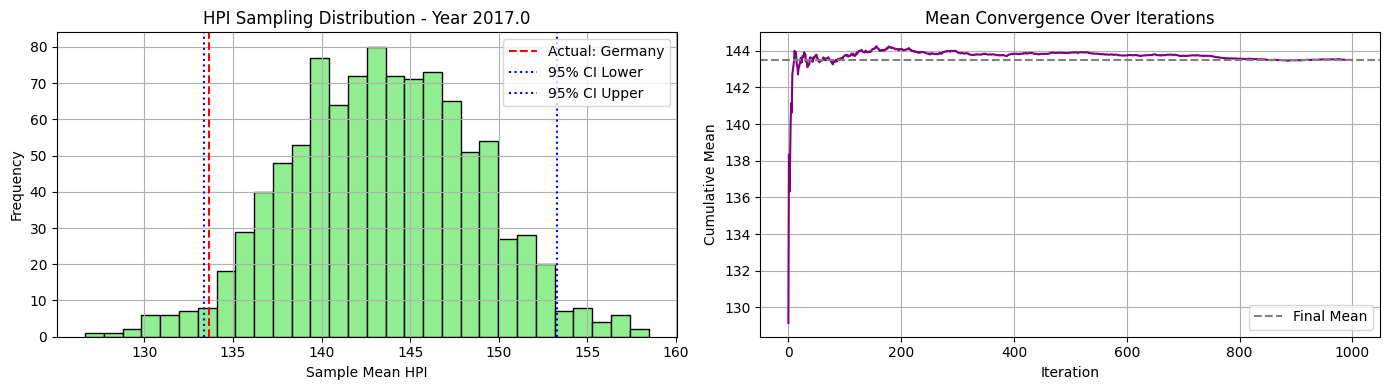


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 178.24 191.85 188.24 136.52 126.31 107.52 155.3  191.85
 191.85 112.04 162.97 149.04 183.82 106.75  90.72 123.06 148.96 120.22
 154.6  153.9  191.85 134.04 147.35]


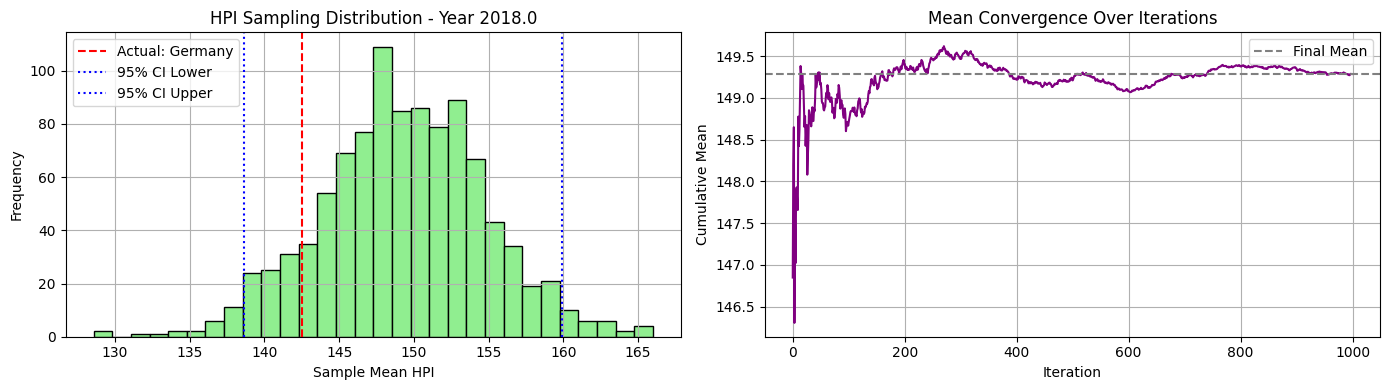


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 179.4  198.37 198.37 149.02 129.62 111.1  181.64 198.37
 198.37 113.84 176.92 152.73 195.26 116.01  97.25 135.77 152.69 121.93
 158.44 155.1  198.37 135.37 153.14]


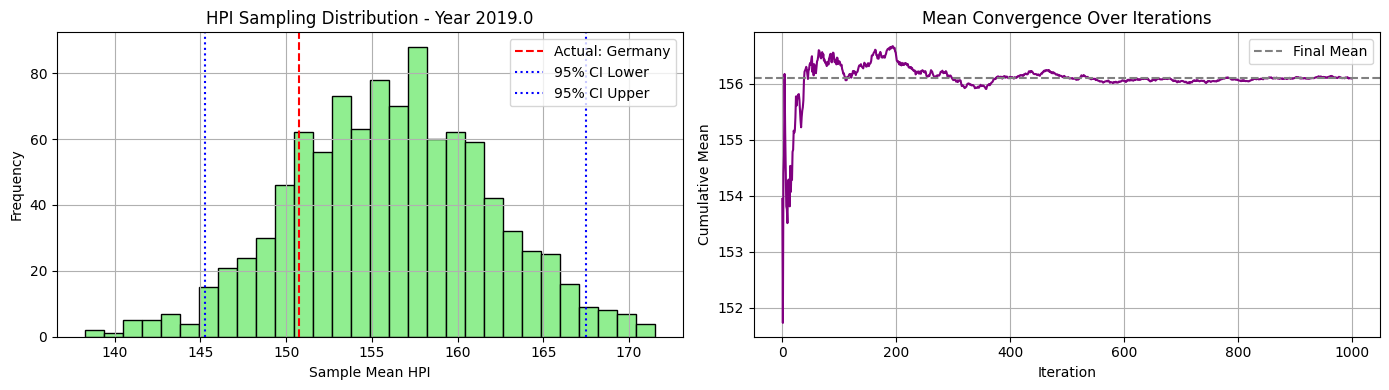


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 190.73 213.74 203.12 161.56 136.24 116.89 190.63 213.74
 213.74 113.93 187.18 159.24 213.74 128.18 106.71 149.28 156.31 126.56
 165.09 160.6  213.74 139.24 163.52]


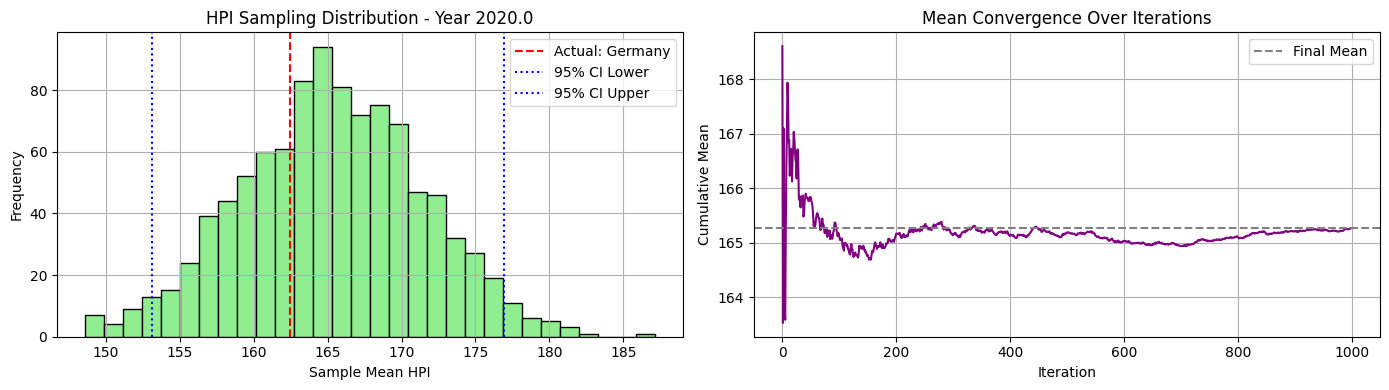


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 214.88 248.26 214.9  193.46 152.2  124.38 222.1  248.26
 248.26 120.7  201.94 175.91 211.74 139.92 121.41 166.04 166.82 143.73
 181.79 164.23 248.26 150.58 188.56]


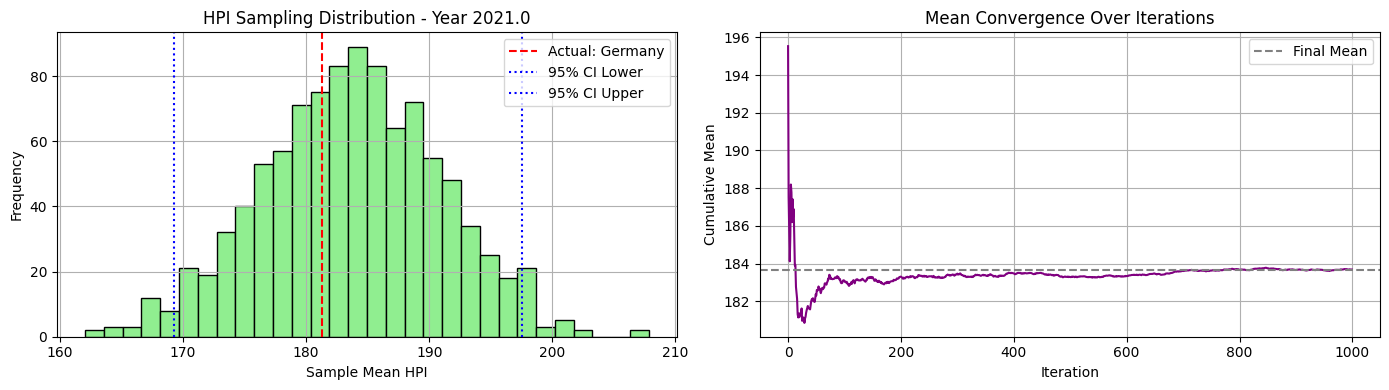


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 235.32 292.18 230.   226.15 151.49 132.1  271.5  292.18
 292.18 130.84 219.93 185.13 223.73 156.43 155.16 191.49 174.03 153.22
 188.27 169.16 292.18 164.55 213.  ]


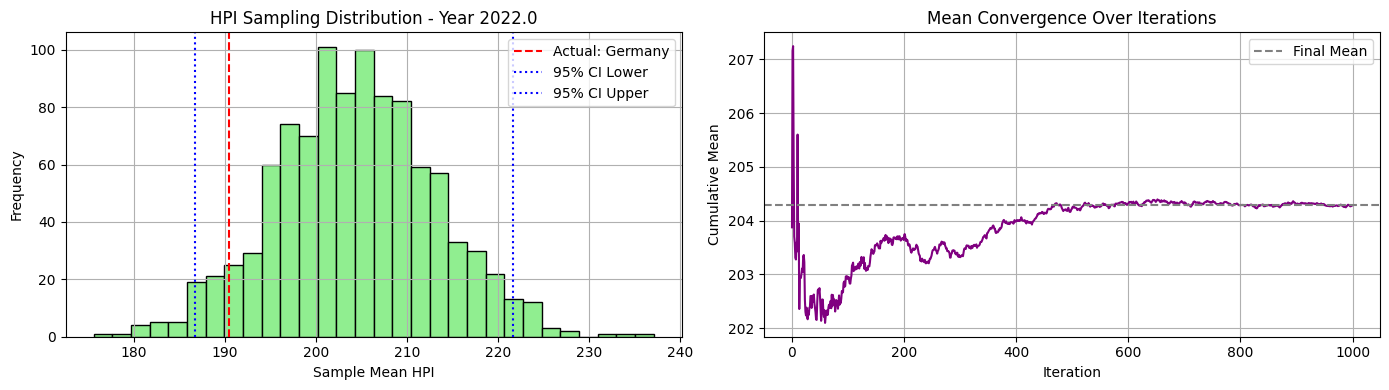


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 221.05 309.37 245.75 222.4  151.24 131.52 290.98 309.37
 309.37 134.8  243.89 184.12 248.04 170.23 157.88 209.99 176.62 143.99
 178.36 174.79 309.37 165.   221.72]


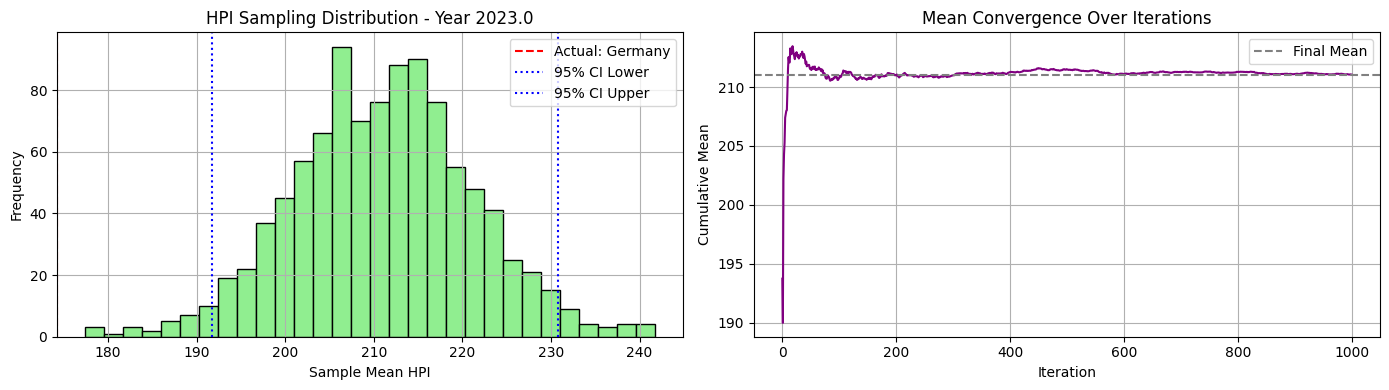


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 217.35 328.24 269.02 233.42 156.73 126.68 328.1  328.24
 328.24 138.61 266.38 189.05 256.03 195.72 186.66 220.7  178.1  142.46
 178.49 178.06 328.24 166.38 231.23]


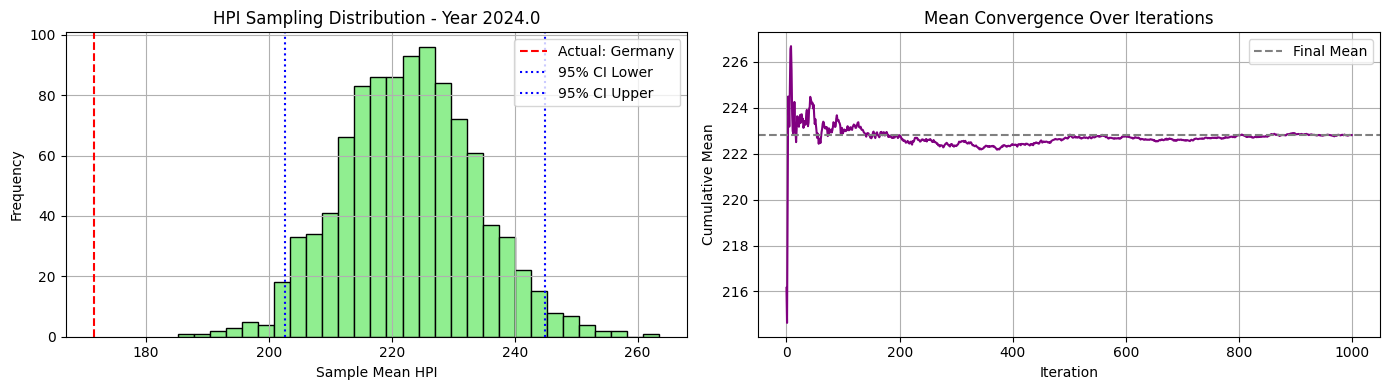

In [7]:
synthetic_c2_ni20_maxi500_h2_23_00, excluded_c2_ni20_maxi500_h2_23_00, actual_c2_ni20_maxi500_h2_23_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=0, seed=52)

🔍 Cluster 1 selected. Excluding country: Ireland
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New Zealand', 'Peru', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


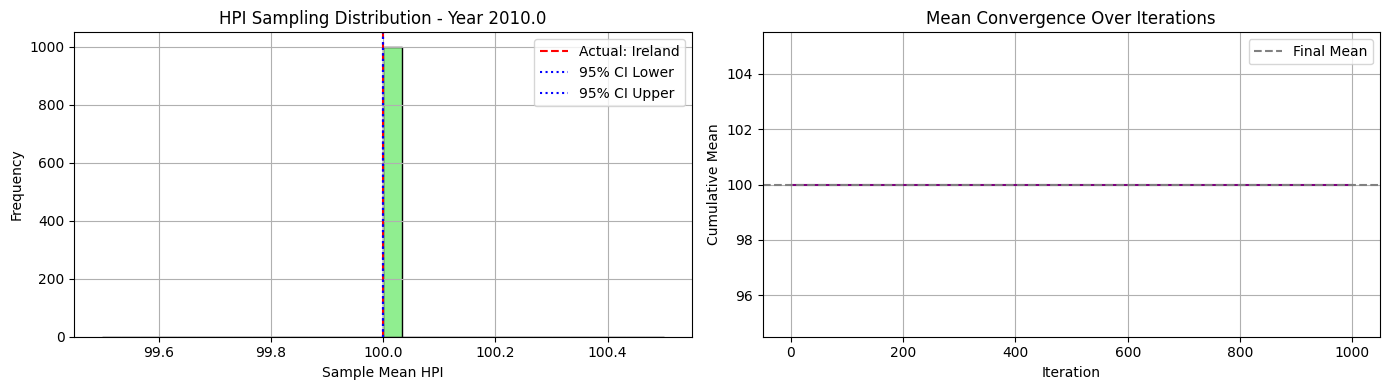


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58  94.49 100.16  96.68 108.47 103.17  94.53 110.52 101.36
 110.42 106.6  103.68 109.83  98.63  98.02 100.75 110.52  95.1   94.49
 109.46  98.46 102.72  94.49 107.51]


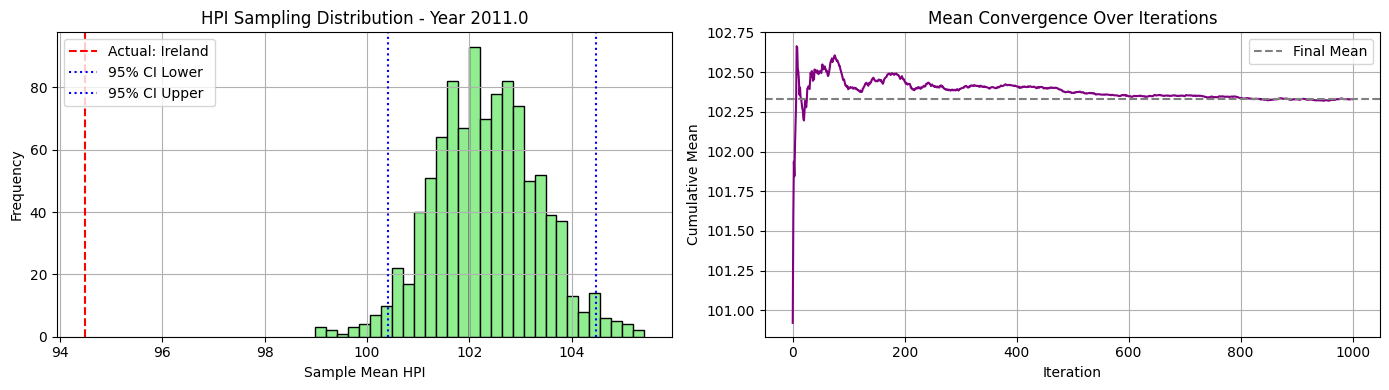


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  92.69  98.62  91.54 116.34 105.64  88.37 114.1   98.77
 113.71 106.36 108.03 124.02 101.62  91.44 105.25 124.02  88.37  88.37
 112.02  95.73  95.63  88.37 113.72]


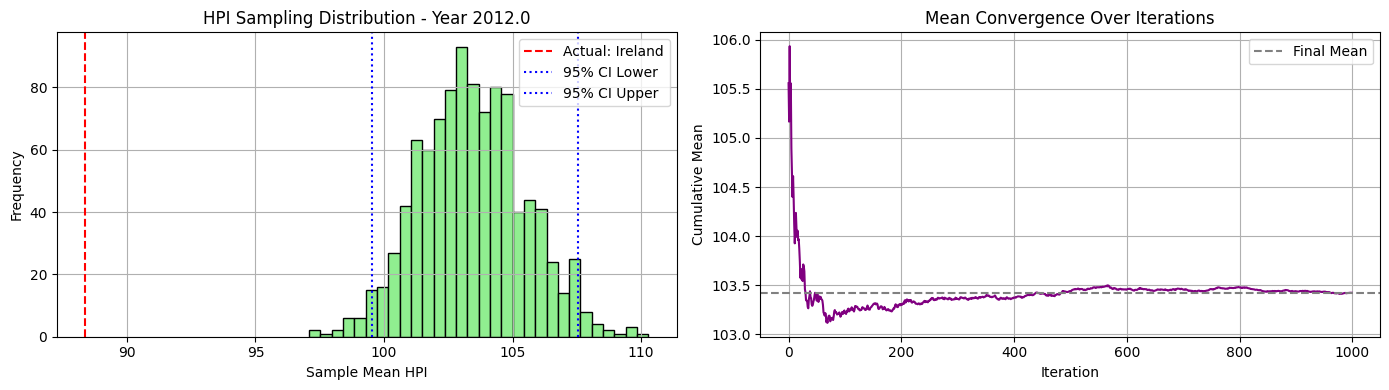


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  90.65  94.7   85.58 128.77 106.87  85.58 124.45  92.38
 121.5  107.65 113.42 136.52 101.21  85.95 114.59 136.52  86.7   85.58
 115.56  96.53  90.62  85.58 118.3 ]


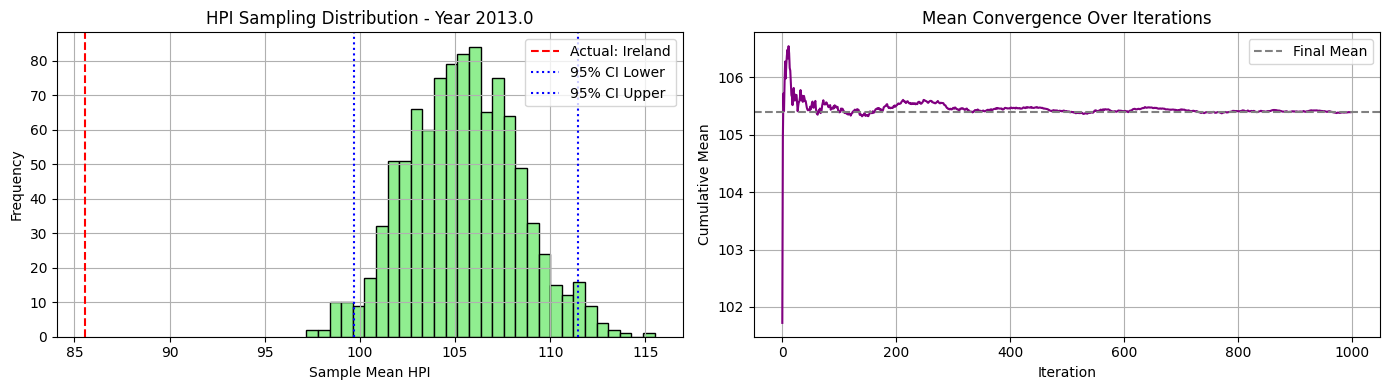


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  91.95  93.19  84.64 146.41 106.5   84.64 132.36  88.02
 128.78 114.57 118.39 151.67 103.79  86.66 122.03 151.67  90.38  84.64
 112.25  97.8   84.64  84.64 121.46]


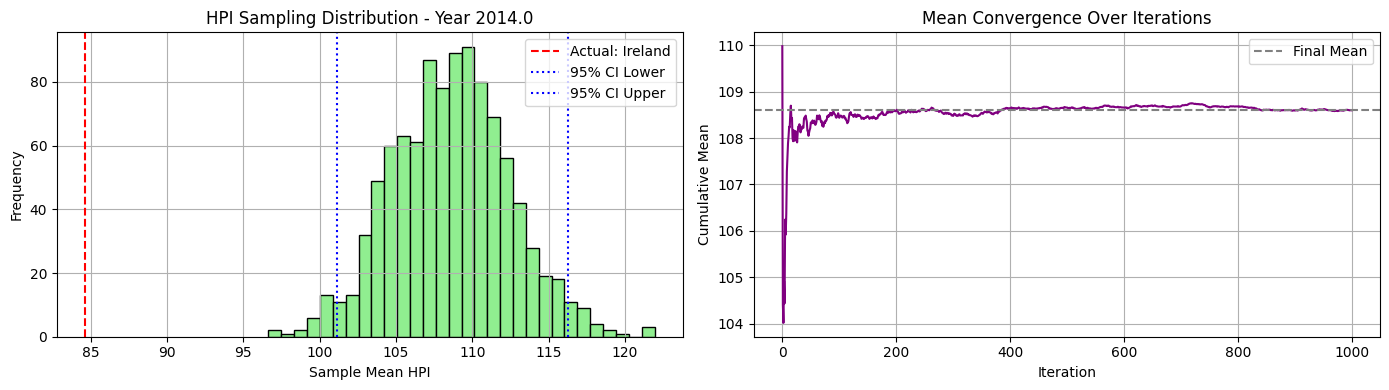


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  94.51  90.54  84.67 156.46 106.5   84.67 140.12  84.67
 124.46 118.76 124.78 162.89 109.83  89.69 137.18 162.89  93.15  84.67
 107.92 103.    85.32  84.67 124.08]


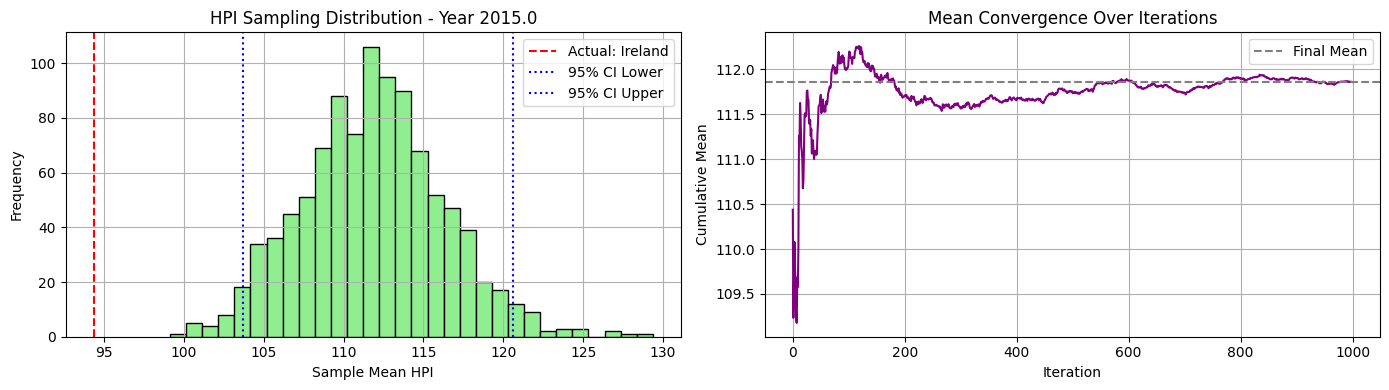


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72 101.15  91.33  88.1  163.86 107.86  88.1  150.56  88.1
 135.02 125.16 132.28 172.75 115.82  94.43 156.62 164.18  99.78  88.91
 104.55 109.87  88.1   88.1  124.32]


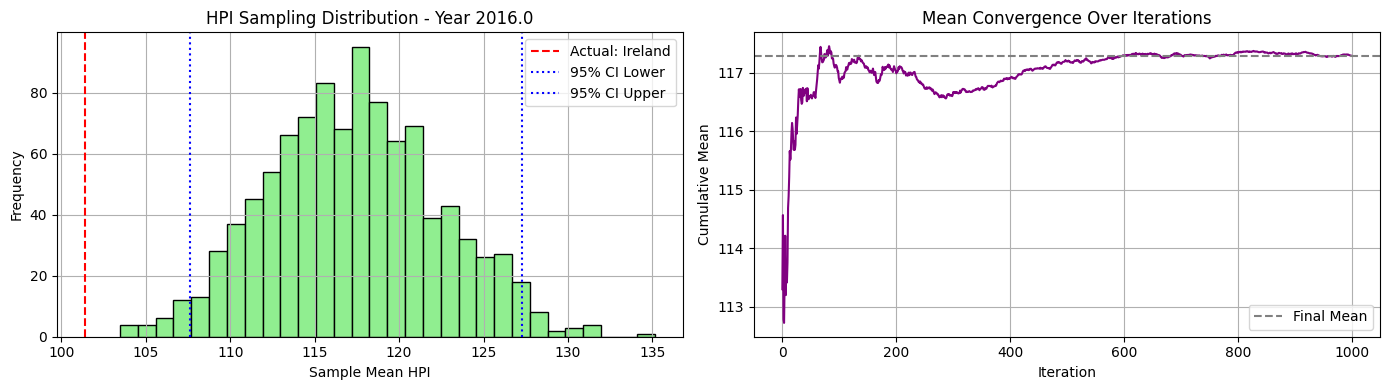


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66 109.91  94.84  88.54 172.91 109.02  88.54 156.44  88.54
 146.87 136.34 139.69 183.99 121.94 102.06 166.8  168.   108.99  93.93
 103.4  116.3   95.38  88.54 125.42]


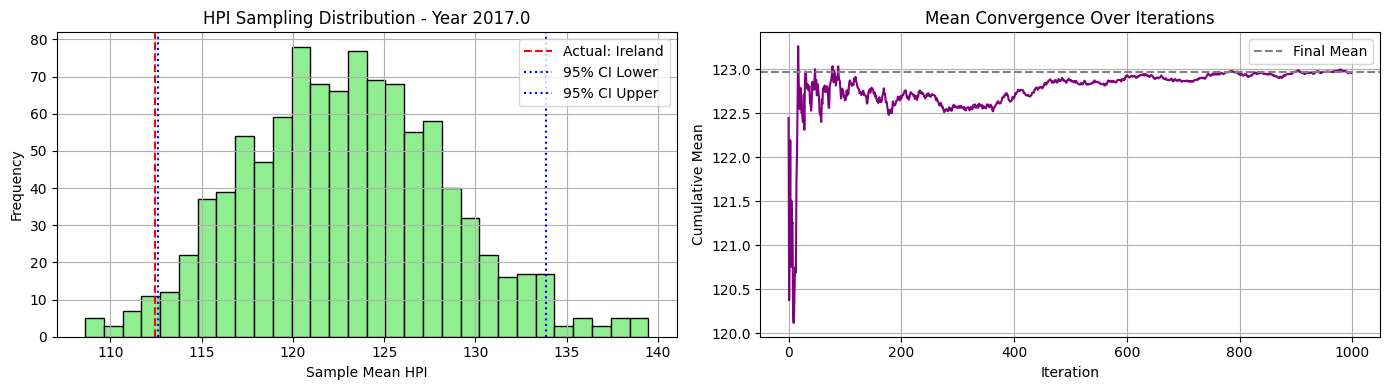


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 117.15 100.59  90.72 183.13 110.06  90.72 155.14  90.72
 160.92 146.29 149.55 191.85 129.02 111.57 172.8  168.42 120.19  99.37
 111.46 124.97 103.7   90.72 129.16]


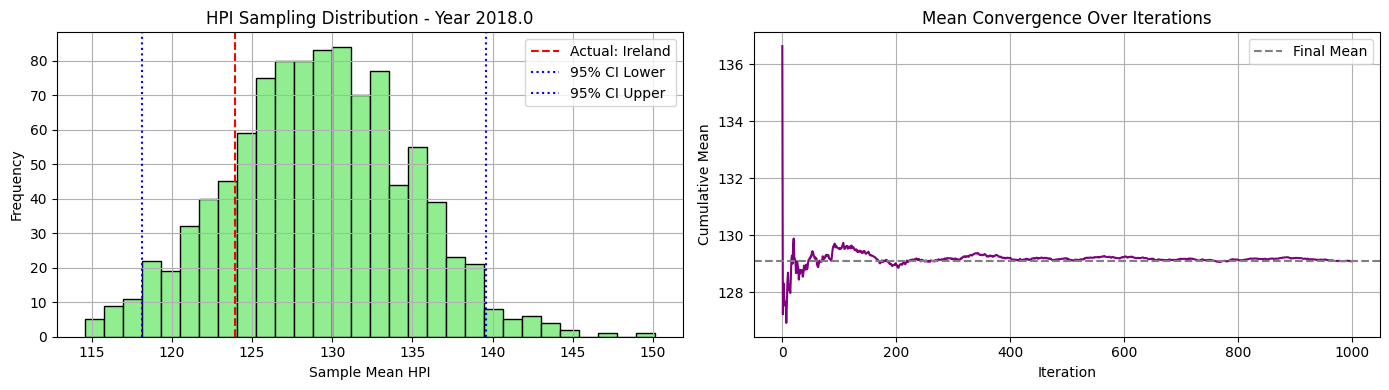


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 124.2  109.64  97.25 195.98 110.52  97.25 158.06  97.25
 175.33 156.3  164.68 196.06 136.9  119.62 178.19 172.03 132.16 102.72
 113.98 136.39 110.65  97.25 133.99]


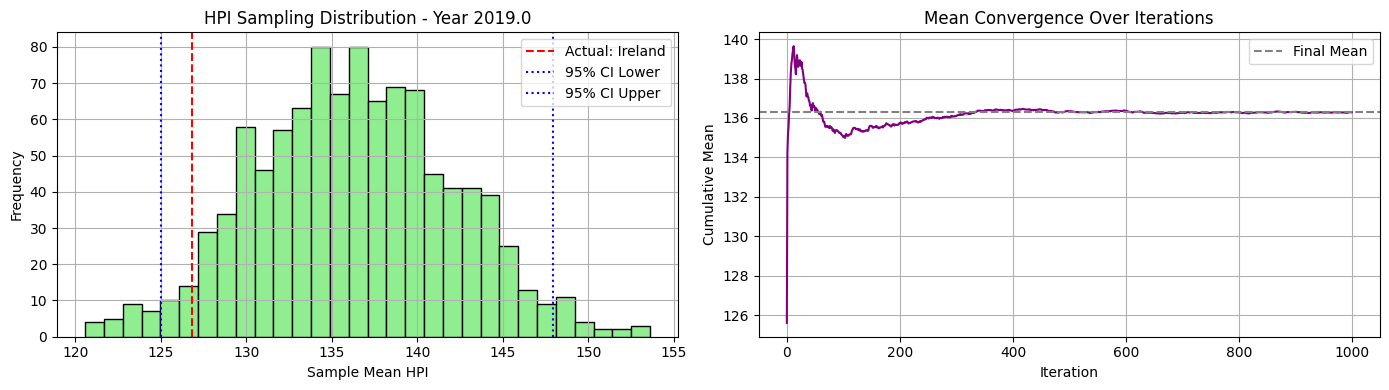


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 129.87 118.06 106.71 207.78 112.49 106.71 162.9  106.71
 181.42 167.66 188.57 198.37 141.54 129.21 196.31 173.67 143.75 107.53
 115.8  149.36 115.74 106.71 137.31]


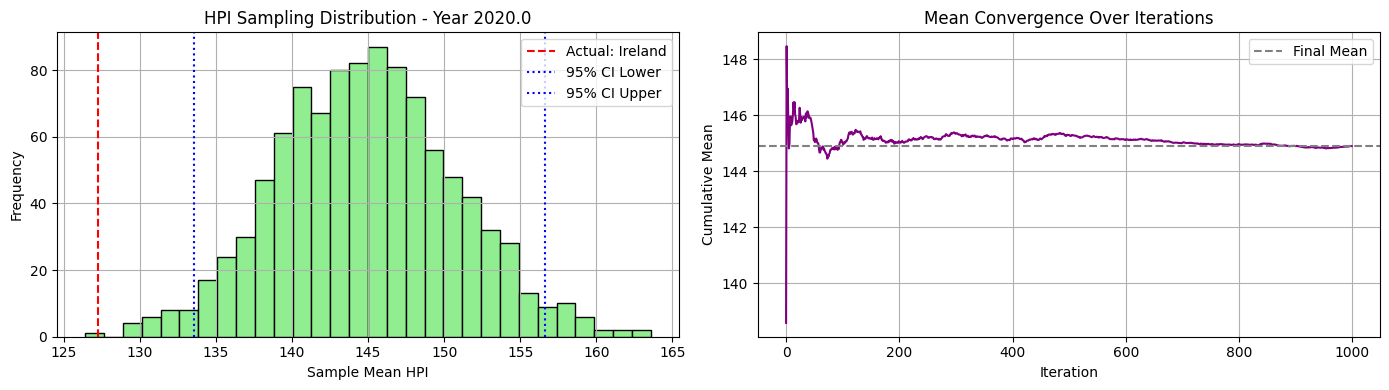


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 141.14 126.64 112.34 239.04 117.62 112.34 176.65 112.34
 201.18 194.58 214.81 200.69 148.74 147.93 248.26 173.6  157.27 112.34
 125.04 158.94 129.1  112.34 145.16]


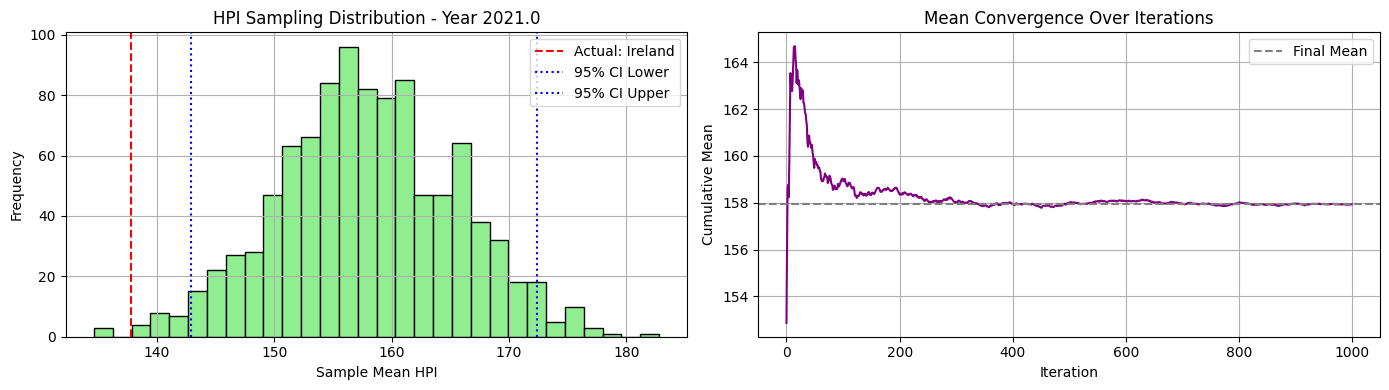


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 160.59 145.44 118.98 292.18 118.98 118.98 207.16 118.98
 229.01 231.64 235.34 207.75 158.62 167.57 249.69 172.65 177.14 120.29
 137.74 180.7  148.16 118.98 154.42]


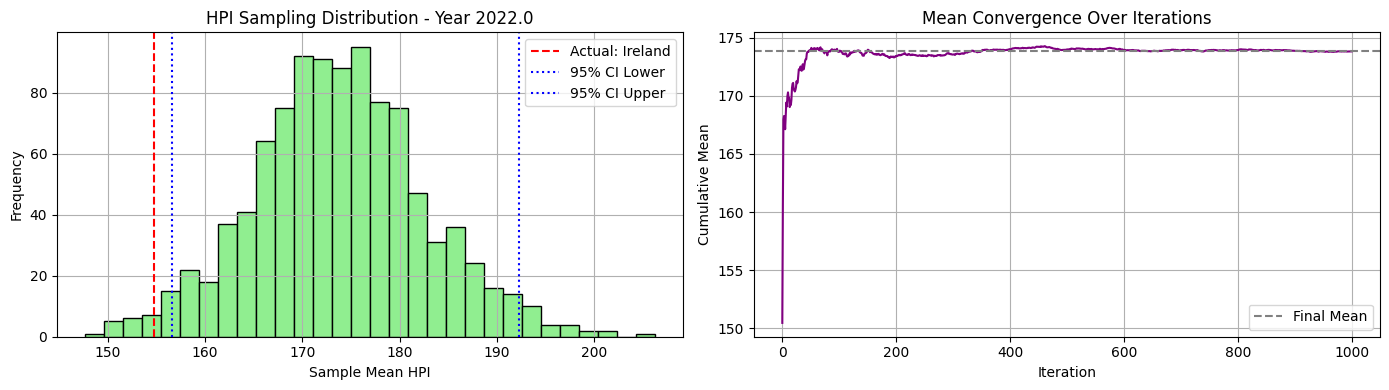


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 176.43 162.82 112.27 309.37 112.27 112.27 214.23 112.27
 237.56 254.38 214.   216.19 168.5  164.36 233.54 175.16 191.66 124.06
 148.01 180.36 158.88 112.27 157.81]


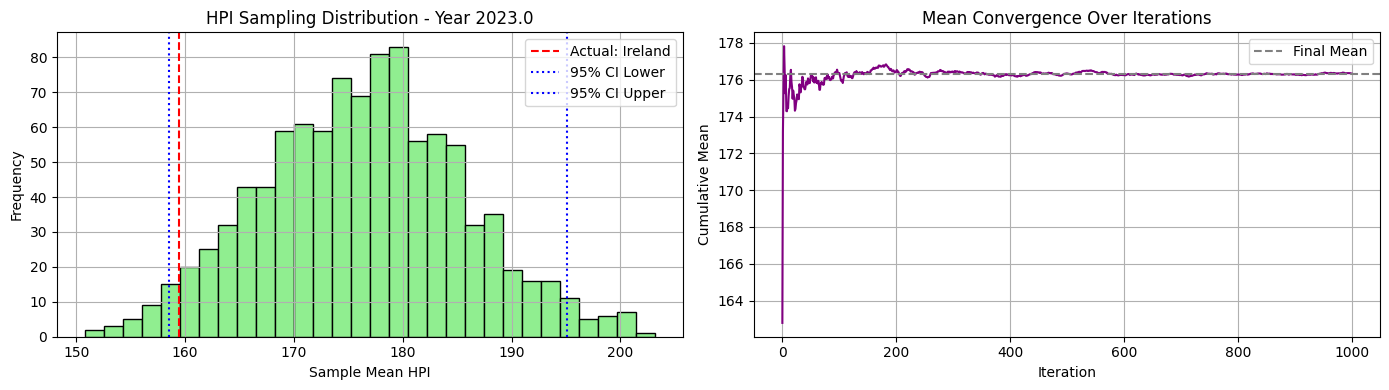


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 205.53 179.7  119.1  328.24 119.1  119.1  224.54 119.1
 247.54 279.12 202.74 225.06 179.35 177.7  233.68 175.38 209.06 130.34
 155.12 187.15 170.56 119.1  160.56]


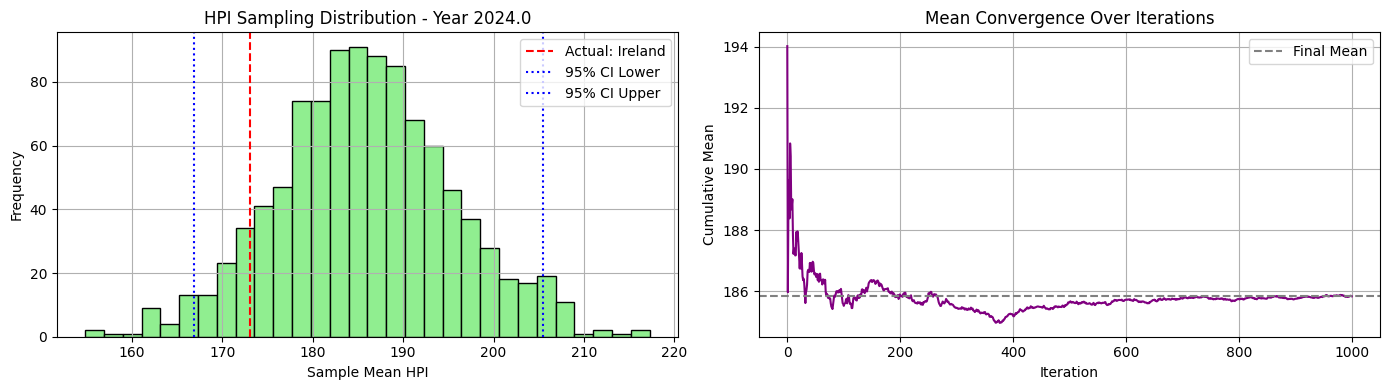

In [8]:
synthetic_c2_ni20_maxi500_h2_23_01, excluded_c2_ni20_maxi500_h2_23_01, actual_c2_ni20_maxi500_h2_23_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=1, seed=52)

### Sampling experiment with seed 32

🔍 Cluster 0 selected. Excluding country: Canada
📊 Sampling from countries: ['Australia', 'Brazil', 'Chile', 'Colombia', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'India', 'Japan', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Russia', 'Serbia', 'South Africa', 'South Korea', 'Sweden', 'Thailand', 'Turkey', 'United Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


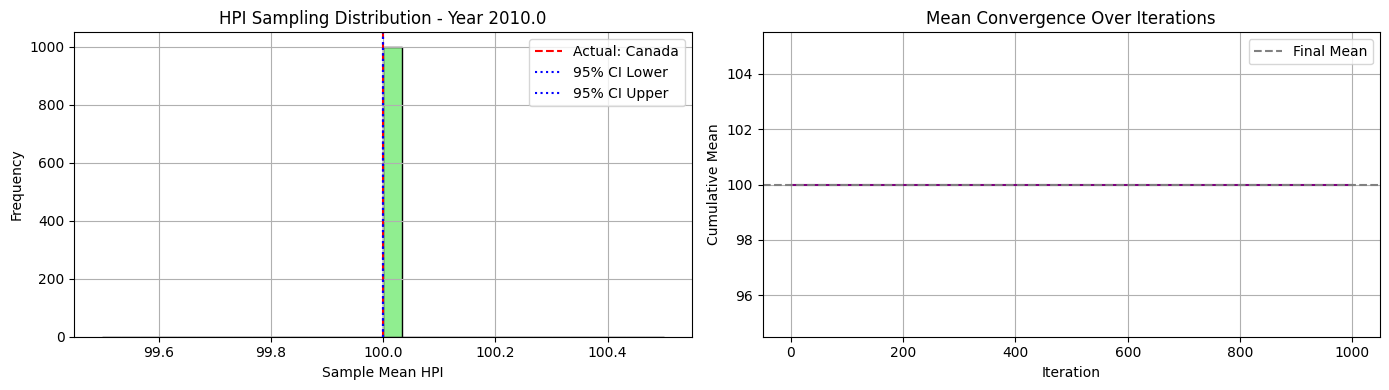


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 110.52 107.89 100.02  98.29 105.69 102.42  96.56 105.5
 110.52 100.07 105.8  108.01 105.57 100.08  94.49  97.62 103.59 105.23
 102.58 104.26 108.8   98.54  97.24]


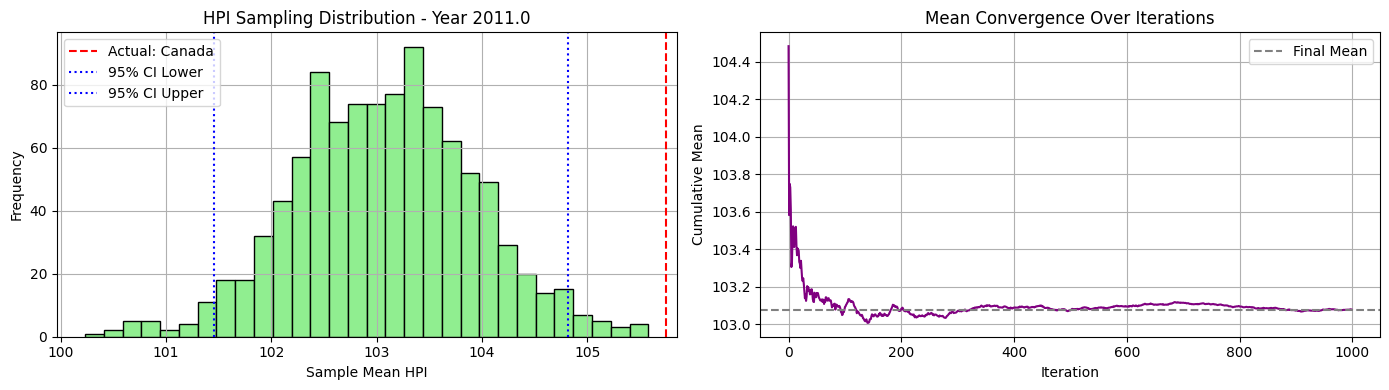


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 124.02 118.79  98.56  95.67 105.11 105.48  92.98 112.38
 124.02  99.19 109.17 115.34 114.94  96.58  91.1   95.68 108.41 108.25
 103.86 107.63 120.68  98.92 101.82]


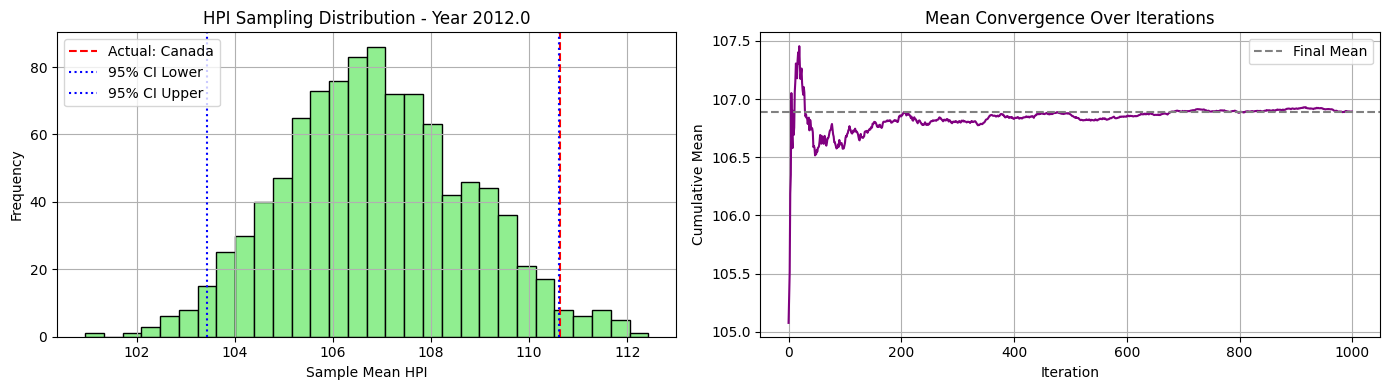


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 136.52 130.06  98.58  99.37 103.13 108.68  90.58 119.18
 136.52 100.81 114.75 119.98 127.86  92.35  94.32  90.62 115.41 107.8
 109.22 115.99 134.46 101.46 111.83]


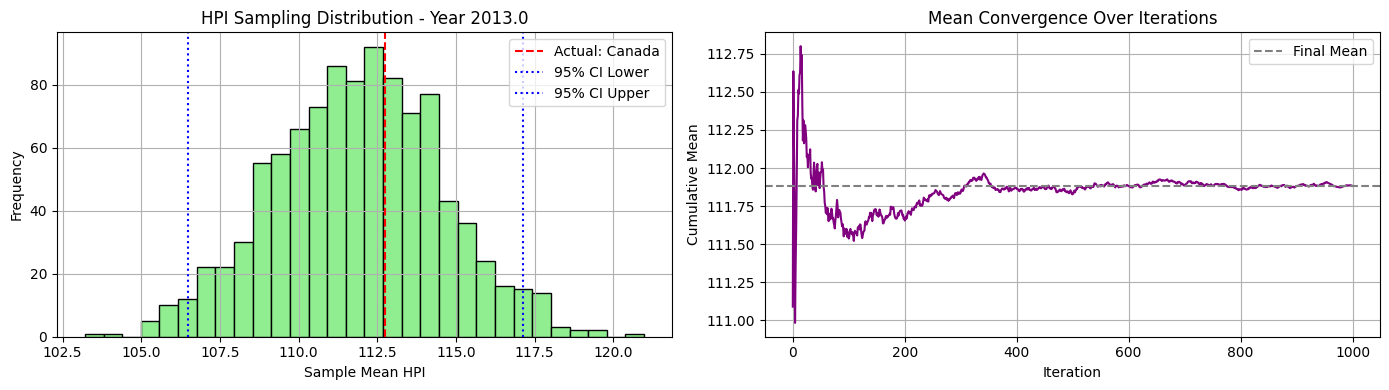


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 151.67 140.75 101.   103.12 101.58 111.85  94.37 128.94
 151.67 102.38 119.64 123.24 142.76  93.27  95.84  95.77 123.99 109.43
 119.52 127.07 151.25 109.6  118.88]


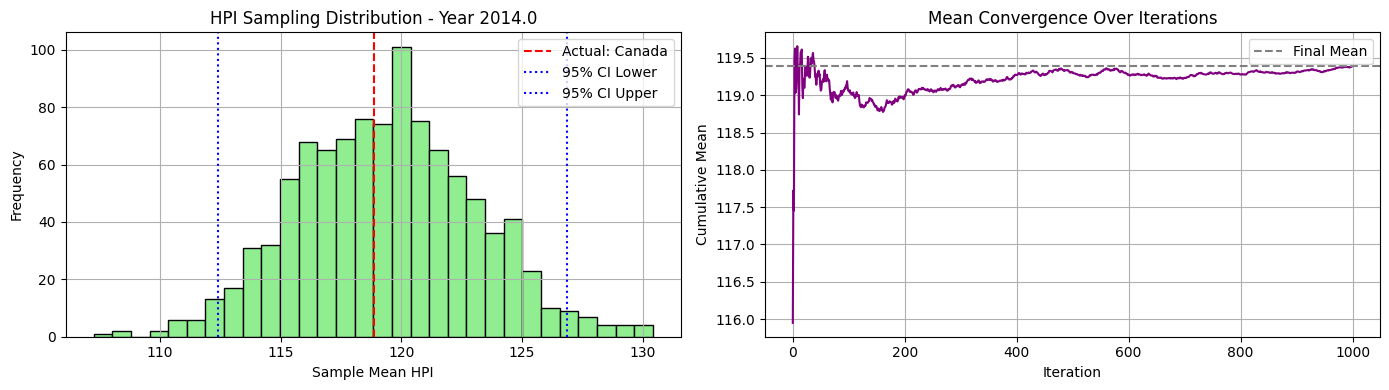


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 162.89 152.93 105.01 110.29 100.22 117.12 106.75 139.74
 162.89 104.86 129.39 130.76 157.04  94.69  97.    99.5  131.8  113.08
 135.2  136.   162.89 116.12 125.18]


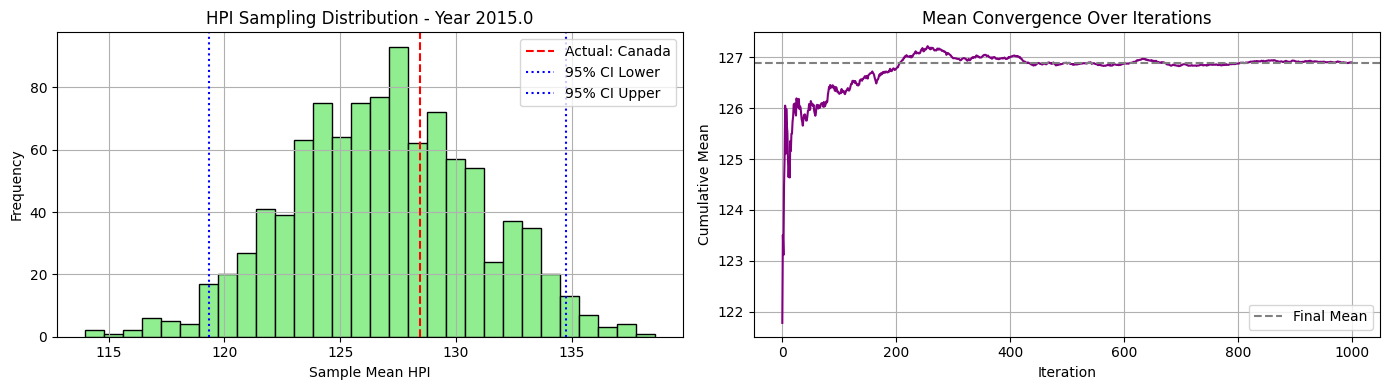


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 172.75 167.48 112.52 115.5  101.25 125.93 121.03 154.59
 172.75 107.18 138.82 139.95 172.75  96.44  91.86 110.62 138.22 116.09
 146.34 142.4  172.75 124.27 131.88]


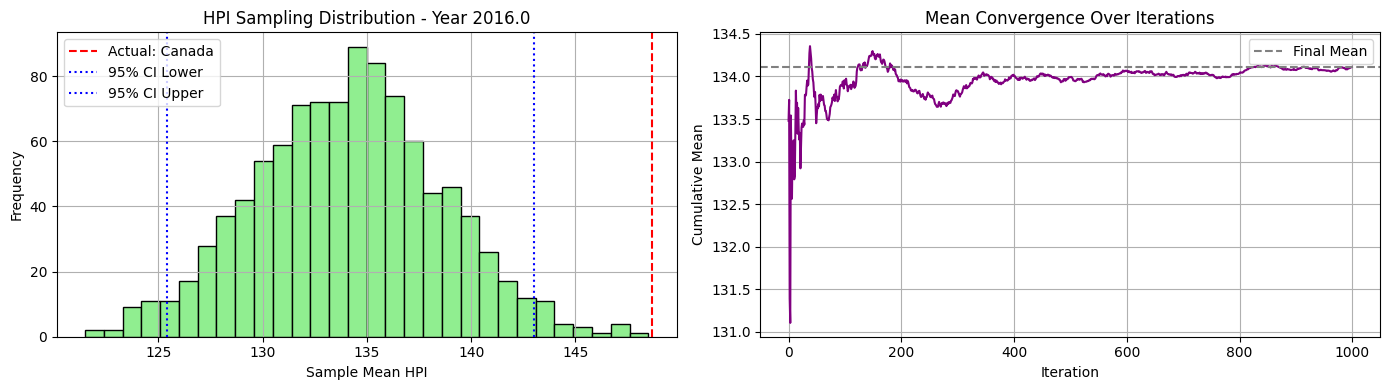


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 183.99 178.56 125.7  120.63 104.46 133.62 135.84 183.99
 183.99 109.91 149.69 146.91 178.82 100.16  88.54 115.3  143.94 117.6
 156.06 146.48 183.99 129.93 139.61]


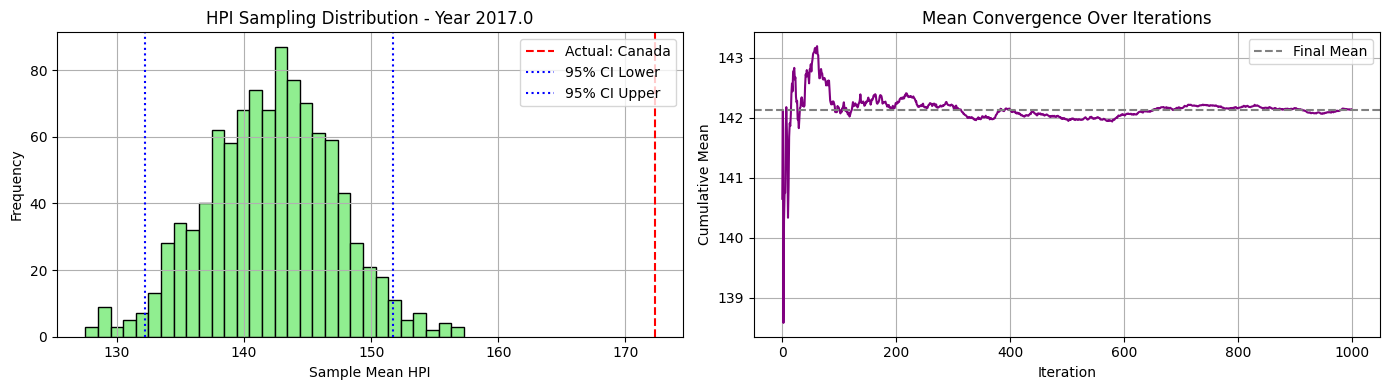


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 191.85 188.24 136.52 126.31 107.52 142.52 155.3  191.85
 191.85 112.04 162.97 149.04 183.82 106.75  90.72 123.06 148.96 120.22
 154.6  153.9  191.85 134.04 147.35]


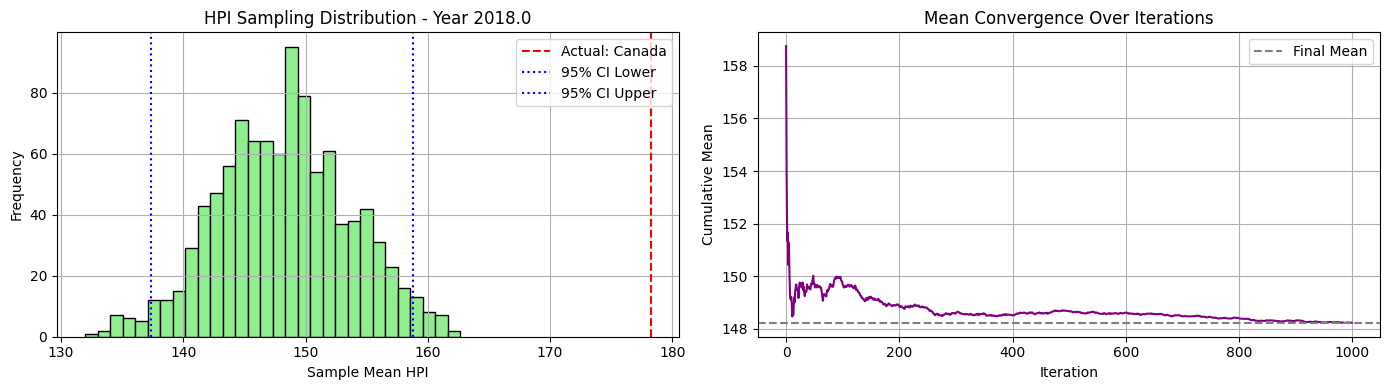


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 198.37 198.37 149.02 129.62 111.1  150.75 181.64 198.37
 198.37 113.84 176.92 152.73 195.26 116.01  97.25 135.77 152.69 121.93
 158.44 155.1  198.37 135.37 153.14]


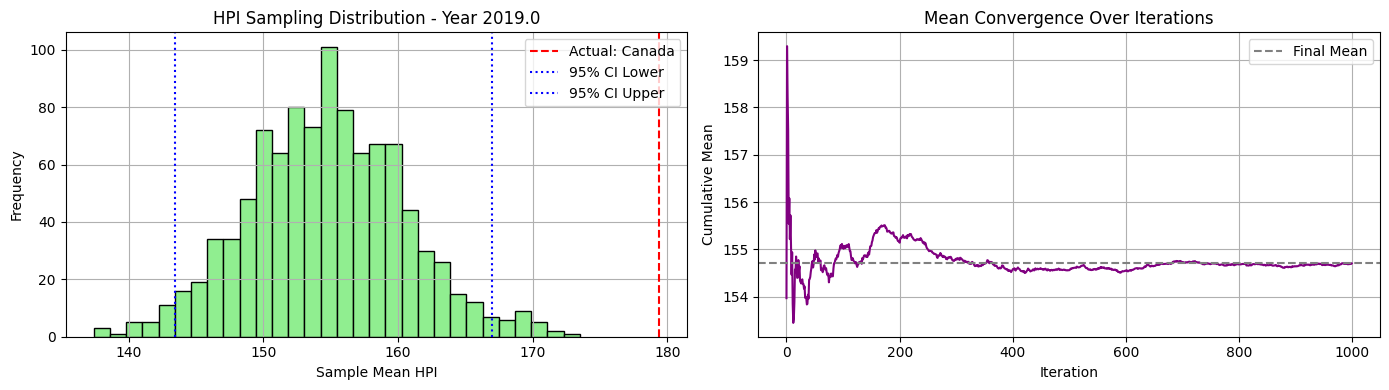


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 213.74 203.12 161.56 136.24 116.89 162.48 190.63 213.74
 213.74 113.93 187.18 159.24 213.74 128.18 106.71 149.28 156.31 126.56
 165.09 160.6  213.74 139.24 163.52]


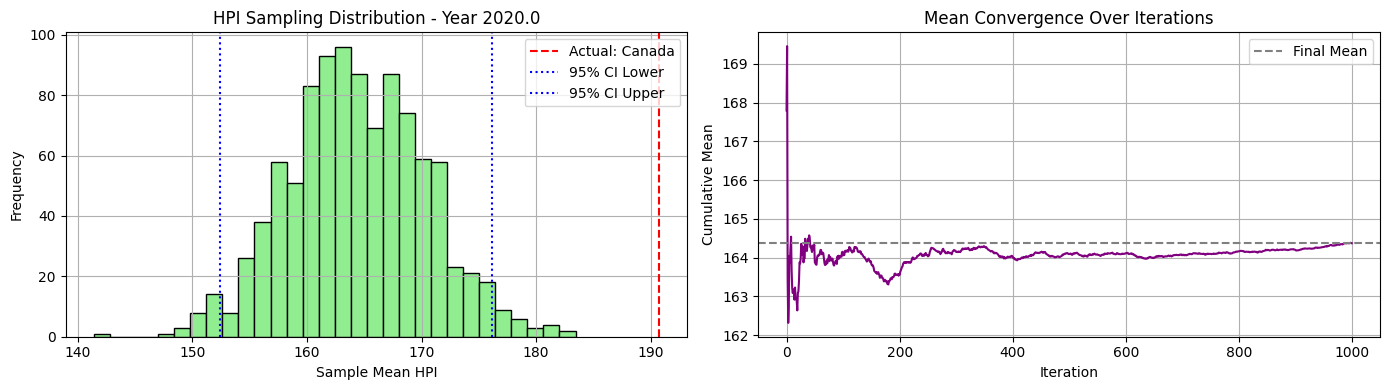


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 248.26 214.9  193.46 152.2  124.38 181.28 222.1  248.26
 248.26 120.7  201.94 175.91 211.74 139.92 121.41 166.04 166.82 143.73
 181.79 164.23 248.26 150.58 188.56]


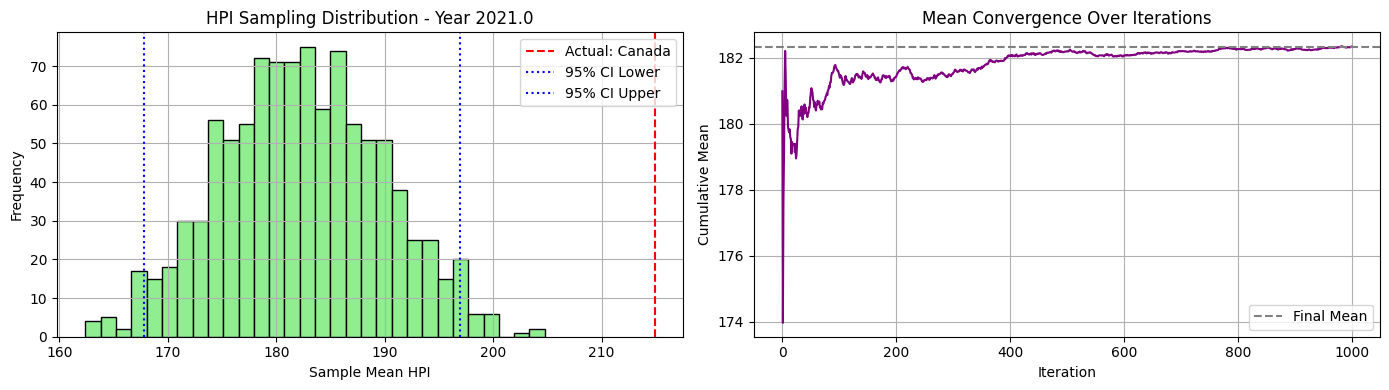


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 292.18 230.   226.15 151.49 132.1  190.42 271.5  292.18
 292.18 130.84 219.93 185.13 223.73 156.43 155.16 191.49 174.03 153.22
 188.27 169.16 292.18 164.55 213.  ]


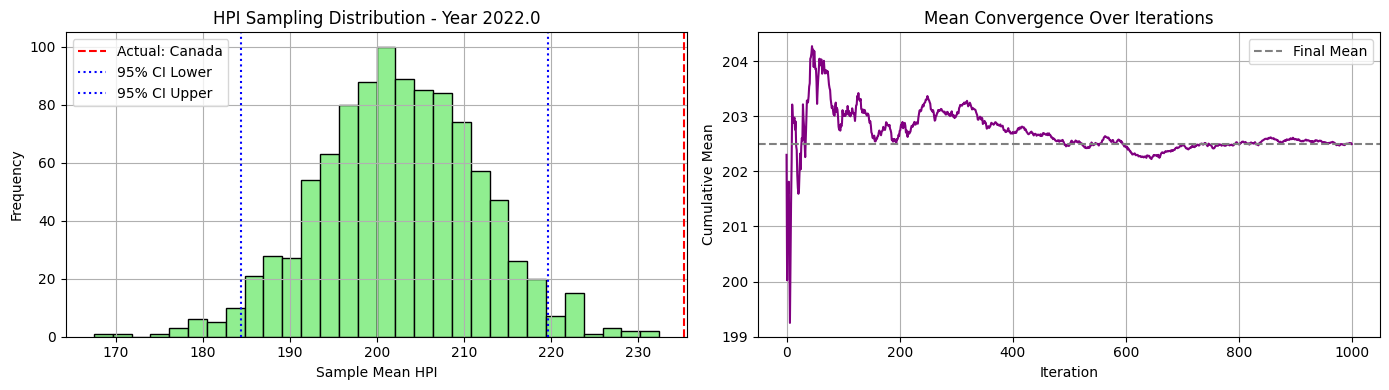


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 309.37 245.75 222.4  151.24 131.52 174.25 290.98 309.37
 309.37 134.8  243.89 184.12 248.04 170.23 157.88 209.99 176.62 143.99
 178.36 174.79 309.37 165.   221.72]


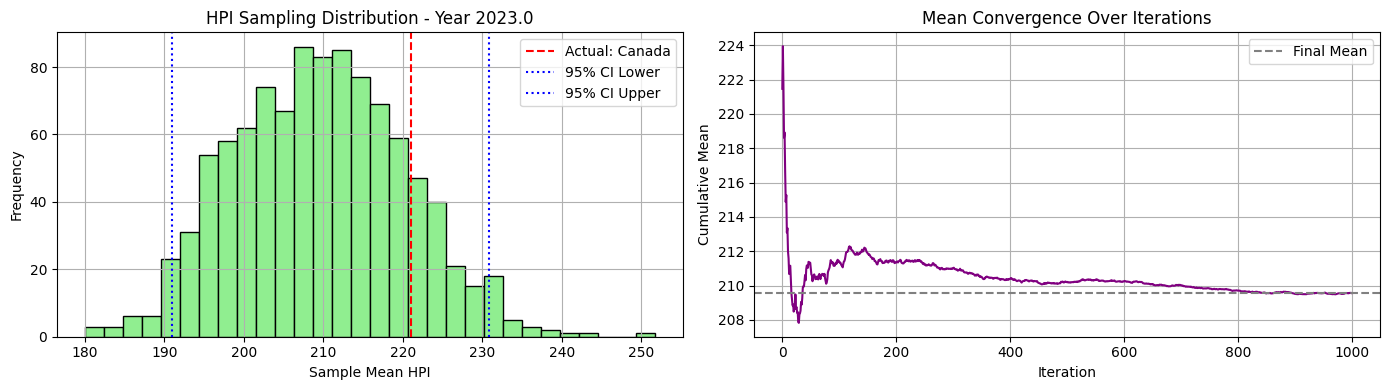


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 328.24 269.02 233.42 156.73 126.68 171.5  328.1  328.24
 328.24 138.61 266.38 189.05 256.03 195.72 186.66 220.7  178.1  142.46
 178.49 178.06 328.24 166.38 231.23]


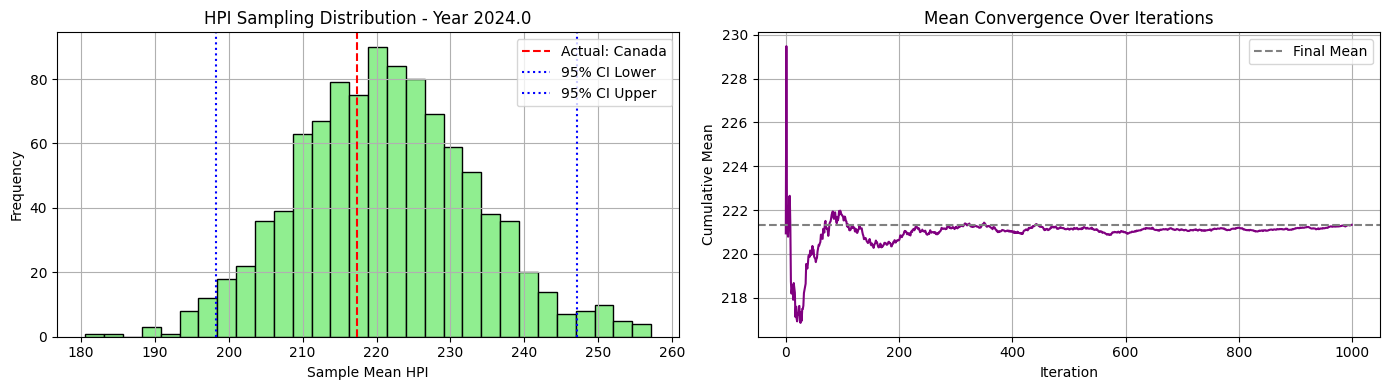

In [9]:
synthetic_c2_ni20_maxi500_h2_32_00, excluded_c2_ni20_maxi500_h2_32_00, actual_c2_ni20_maxi500_h2_32_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=0, seed=32)

🔍 Cluster 1 selected. Excluding country: Bulgaria
📊 Sampling from countries: ['Austria', 'Belgium', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New Zealand', 'Peru', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


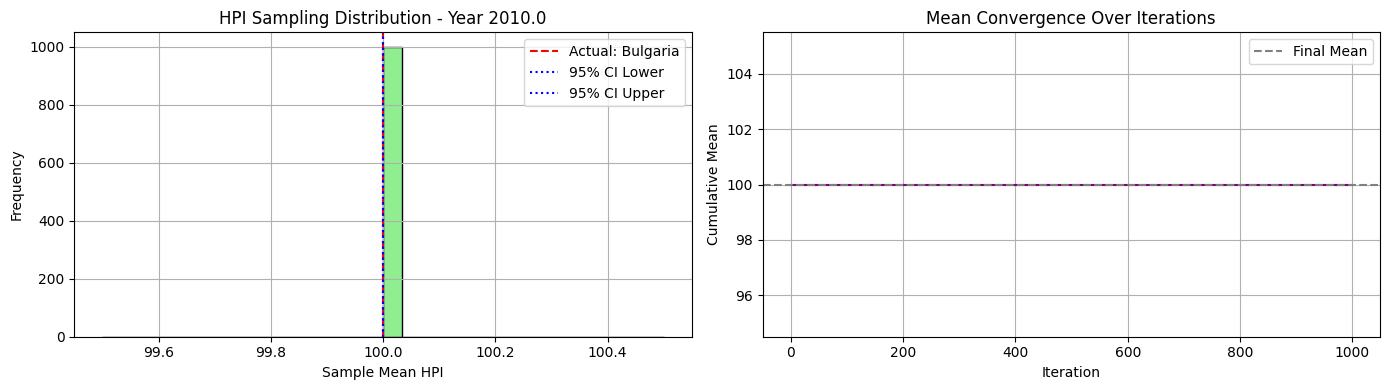


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58 100.16  96.68 108.47 103.17  94.53  94.49 110.52 101.36
 110.42 106.6  103.68 109.83  98.63  98.02 100.75 110.52  95.1   94.49
 109.46  98.46 102.72  94.49 107.51]


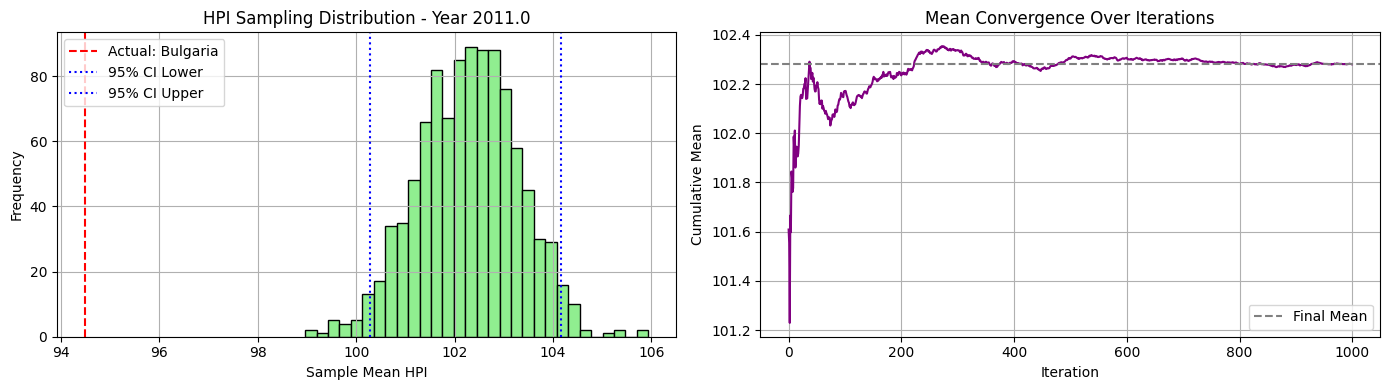


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  98.62  91.54 116.34 105.64  88.37  88.37 114.1   98.77
 113.71 106.36 108.03 124.02 101.62  91.44 105.25 124.02  88.37  88.37
 112.02  95.73  95.63  88.37 113.72]


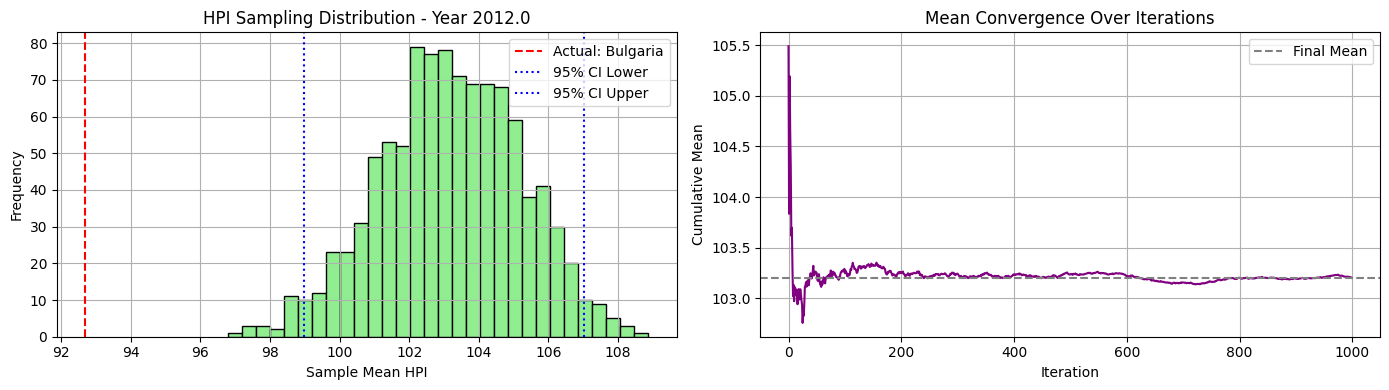


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  94.7   85.58 128.77 106.87  85.58  85.58 124.45  92.38
 121.5  107.65 113.42 136.52 101.21  85.95 114.59 136.52  86.7   85.58
 115.56  96.53  90.62  85.58 118.3 ]


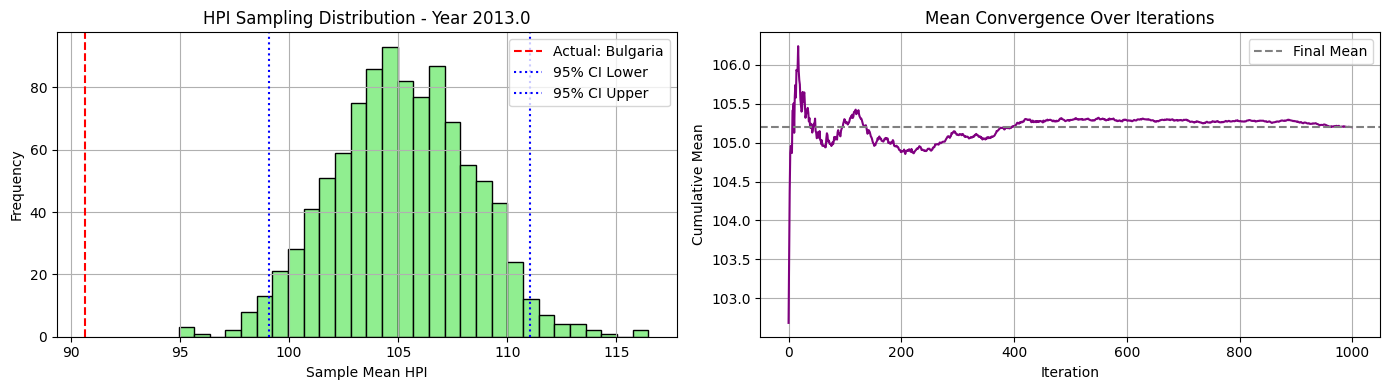


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  93.19  84.64 146.41 106.5   84.64  84.66 132.36  88.02
 128.78 114.57 118.39 151.67 103.79  86.66 122.03 151.67  90.38  84.64
 112.25  97.8   84.64  84.64 121.46]


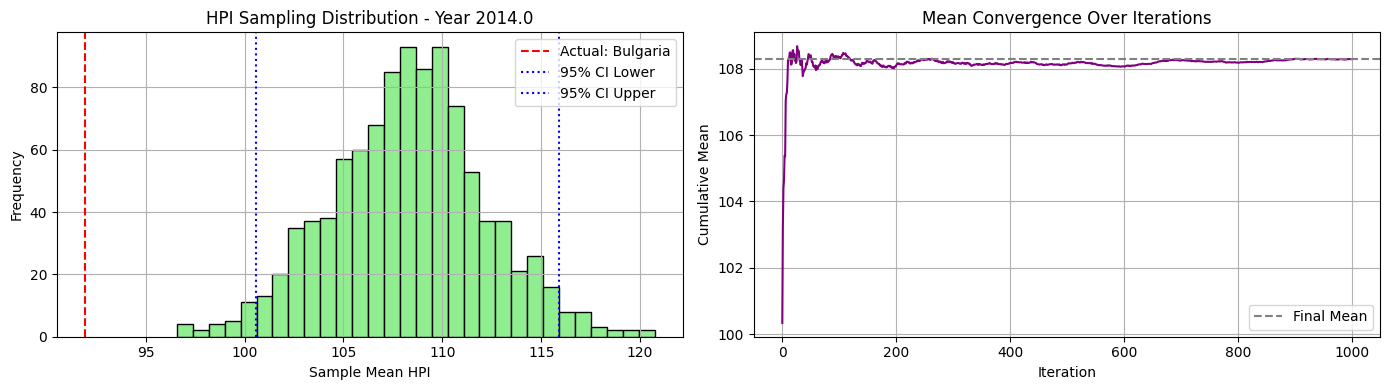


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  90.54  84.67 156.46 106.5   84.67  94.36 140.12  84.67
 124.46 118.76 124.78 162.89 109.83  89.69 137.18 162.89  93.15  84.67
 107.92 103.    85.32  84.67 124.08]


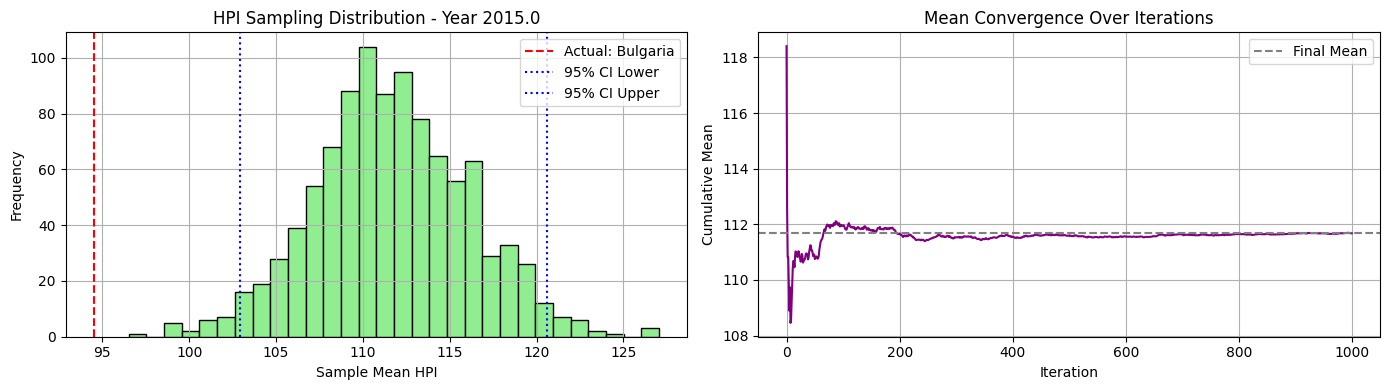


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72  91.33  88.1  163.86 107.86  88.1  101.42 150.56  88.1
 135.02 125.16 132.28 172.75 115.82  94.43 156.62 164.18  99.78  88.91
 104.55 109.87  88.1   88.1  124.32]


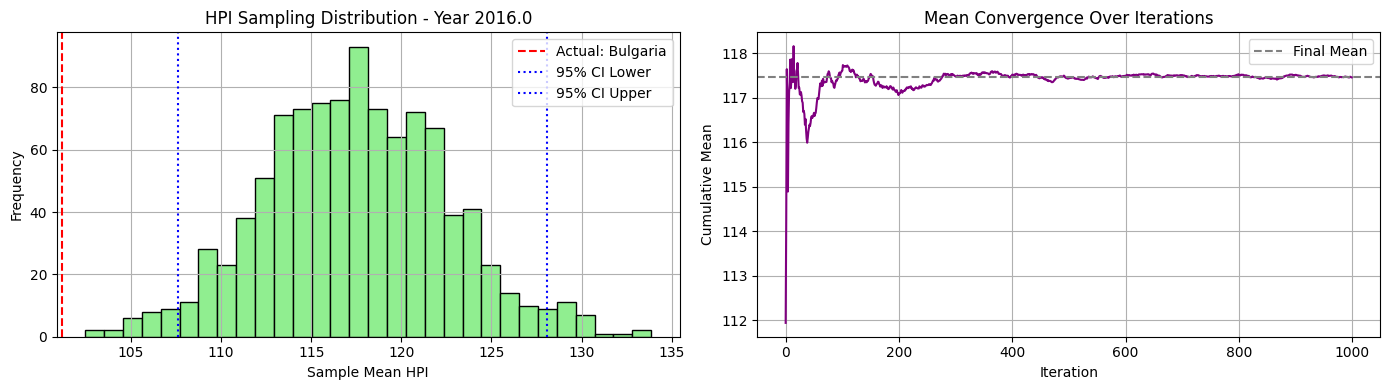


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66  94.84  88.54 172.91 109.02  88.54 112.44 156.44  88.54
 146.87 136.34 139.69 183.99 121.94 102.06 166.8  168.   108.99  93.93
 103.4  116.3   95.38  88.54 125.42]


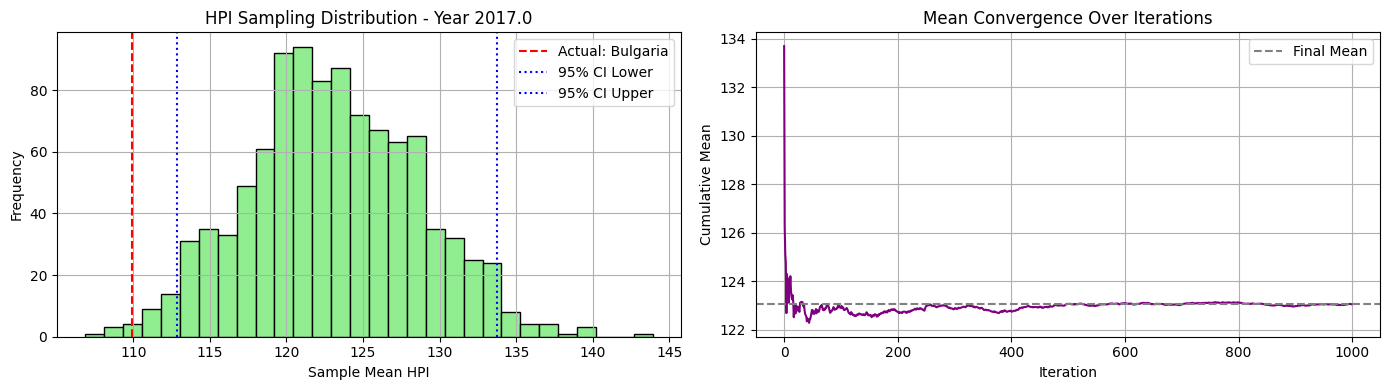


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 100.59  90.72 183.13 110.06  90.72 123.96 155.14  90.72
 160.92 146.29 149.55 191.85 129.02 111.57 172.8  168.42 120.19  99.37
 111.46 124.97 103.7   90.72 129.16]


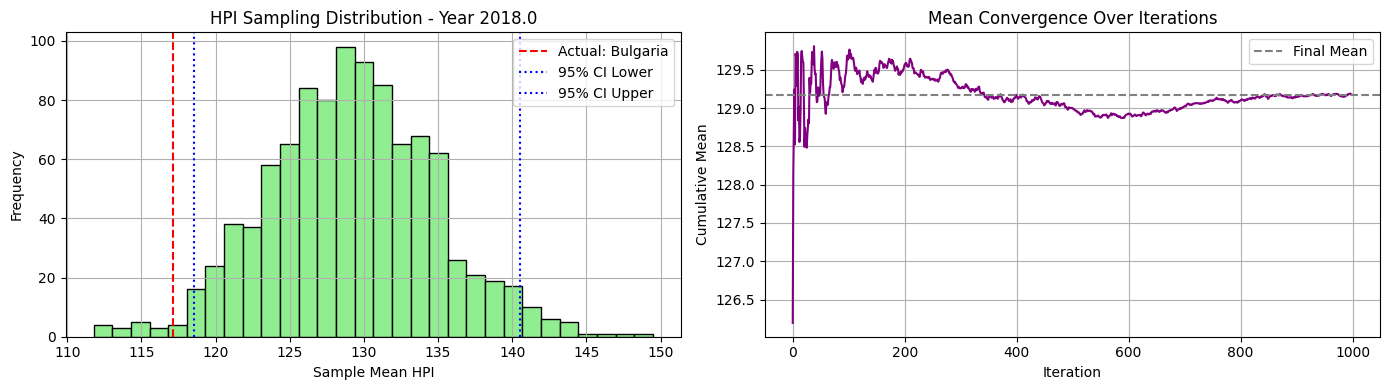


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 109.64  97.25 195.98 110.52  97.25 126.85 158.06  97.25
 175.33 156.3  164.68 196.06 136.9  119.62 178.19 172.03 132.16 102.72
 113.98 136.39 110.65  97.25 133.99]


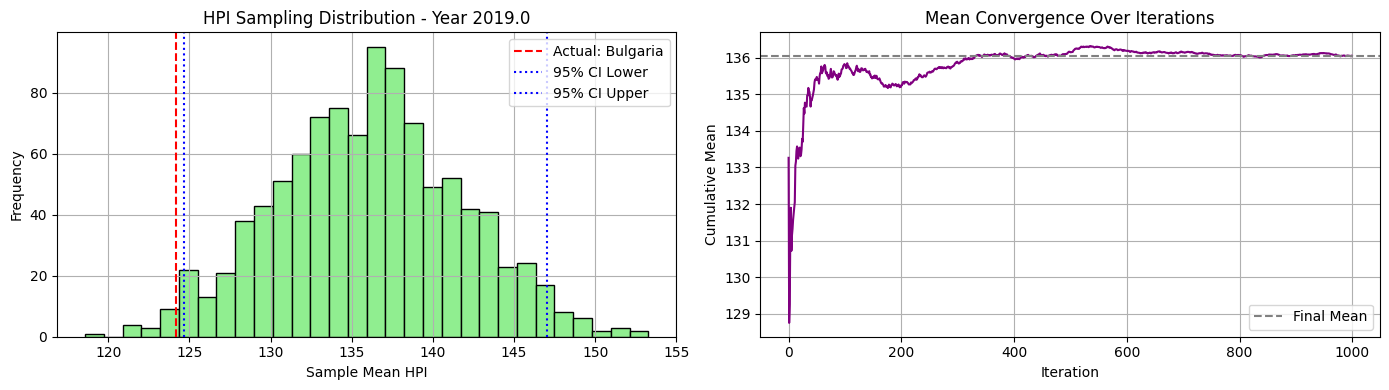


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 118.06 106.71 207.78 112.49 106.71 127.24 162.9  106.71
 181.42 167.66 188.57 198.37 141.54 129.21 196.31 173.67 143.75 107.53
 115.8  149.36 115.74 106.71 137.31]


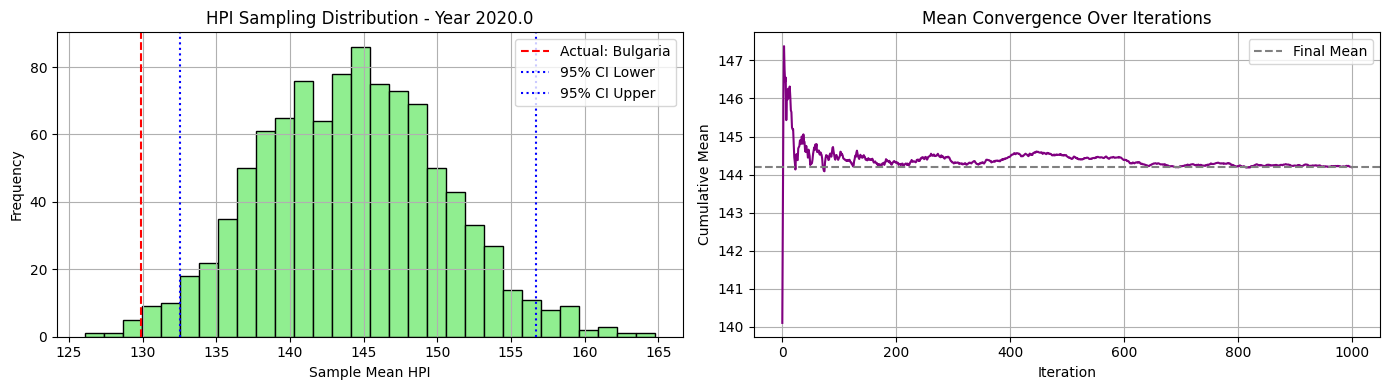


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 126.64 112.34 239.04 117.62 112.34 137.77 176.65 112.34
 201.18 194.58 214.81 200.69 148.74 147.93 248.26 173.6  157.27 112.34
 125.04 158.94 129.1  112.34 145.16]


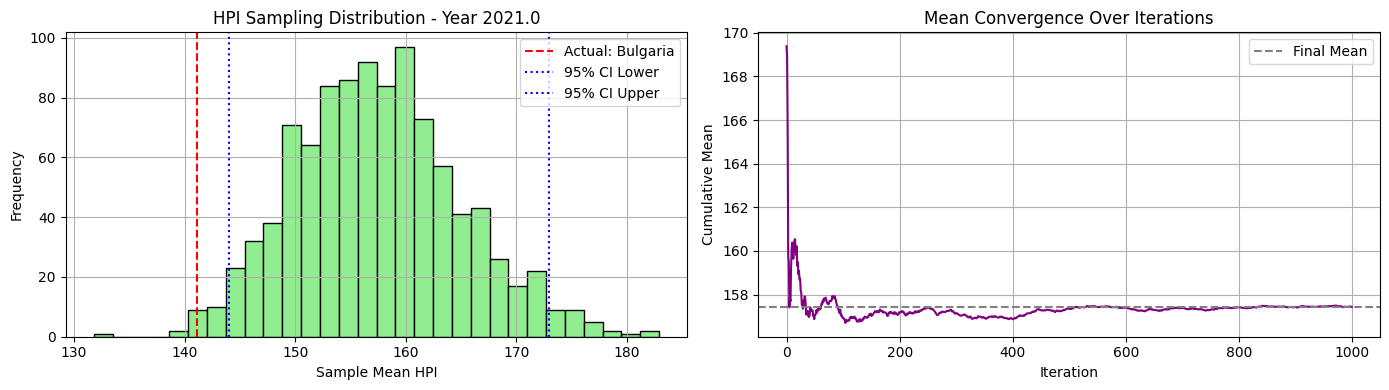


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 145.44 118.98 292.18 118.98 118.98 154.73 207.16 118.98
 229.01 231.64 235.34 207.75 158.62 167.57 249.69 172.65 177.14 120.29
 137.74 180.7  148.16 118.98 154.42]


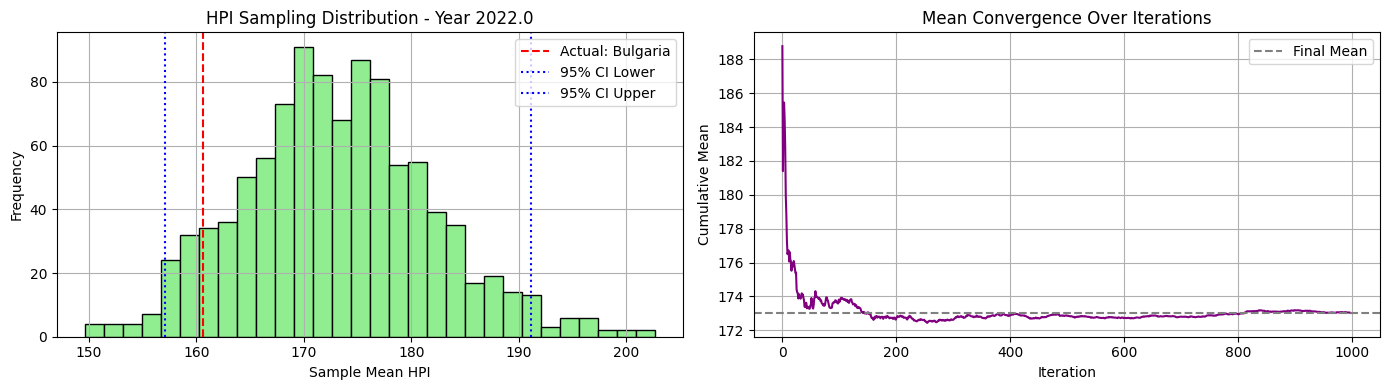


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 162.82 112.27 309.37 112.27 112.27 159.48 214.23 112.27
 237.56 254.38 214.   216.19 168.5  164.36 233.54 175.16 191.66 124.06
 148.01 180.36 158.88 112.27 157.81]


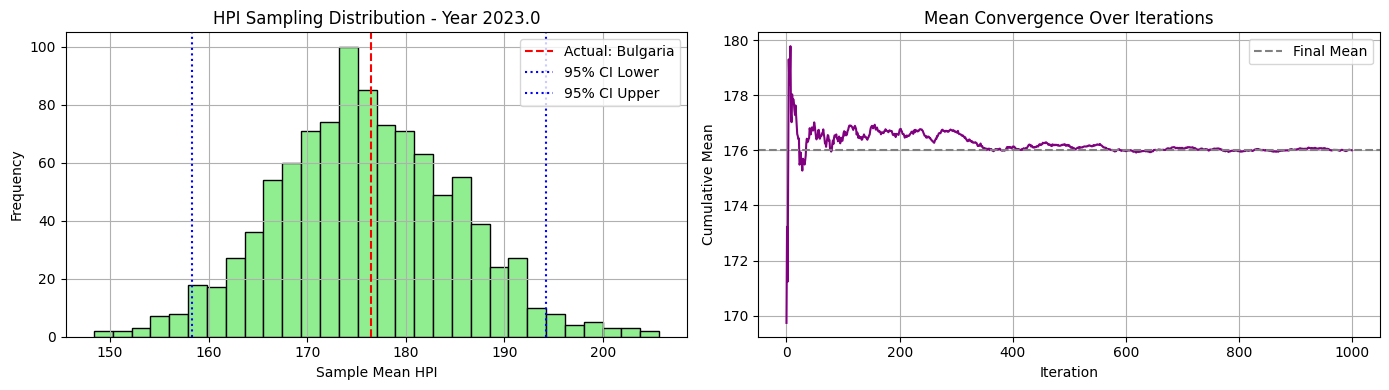


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 179.7  119.1  328.24 119.1  119.1  173.07 224.54 119.1
 247.54 279.12 202.74 225.06 179.35 177.7  233.68 175.38 209.06 130.34
 155.12 187.15 170.56 119.1  160.56]


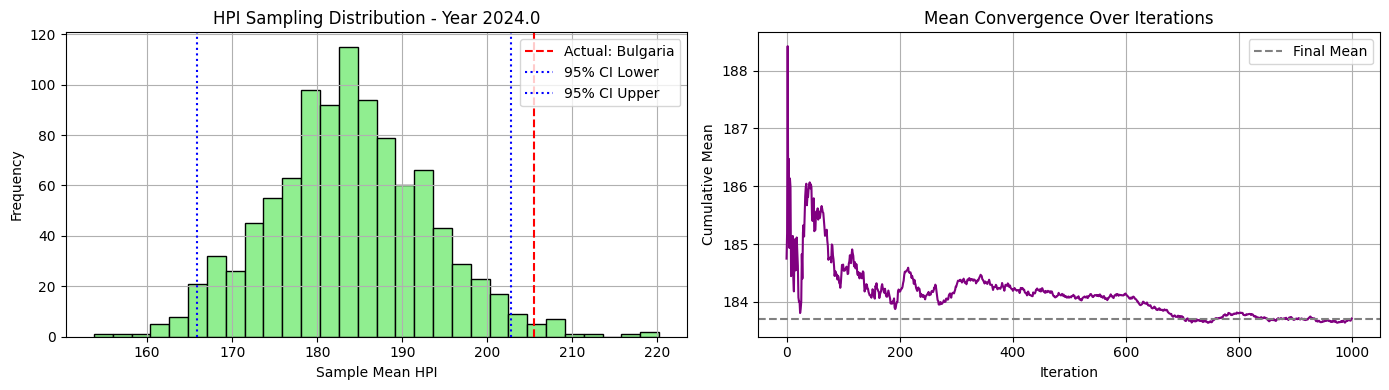

In [10]:
synthetic_c2_ni20_maxi500_h2_32_01, excluded_c2_ni20_maxi500_h2_32_01, actual_c2_ni20_maxi500_h2_32_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=1, seed=32)

### Sampling experiment with seed 43

🔍 Cluster 0 selected. Excluding country: Brazil
📊 Sampling from countries: ['Australia', 'Canada', 'Chile', 'Colombia', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'India', 'Japan', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Russia', 'Serbia', 'South Africa', 'South Korea', 'Sweden', 'Thailand', 'Turkey', 'United Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


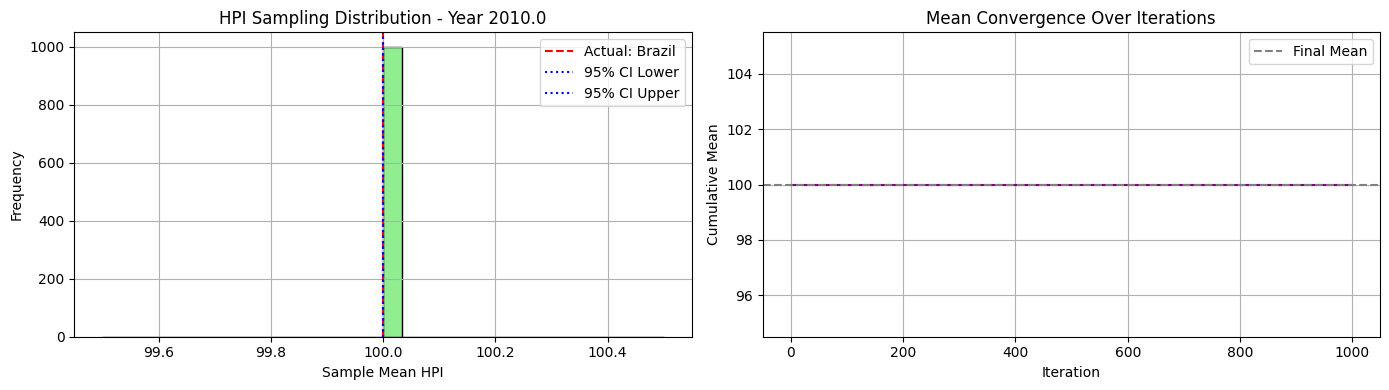


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 105.75 110.52 107.89 100.02  98.29 105.69 102.42  96.56 105.5
 110.52 100.07 105.8  108.01 105.57 100.08  94.49  97.62 103.59 105.23
 102.58 104.26 108.8   98.54  97.24]


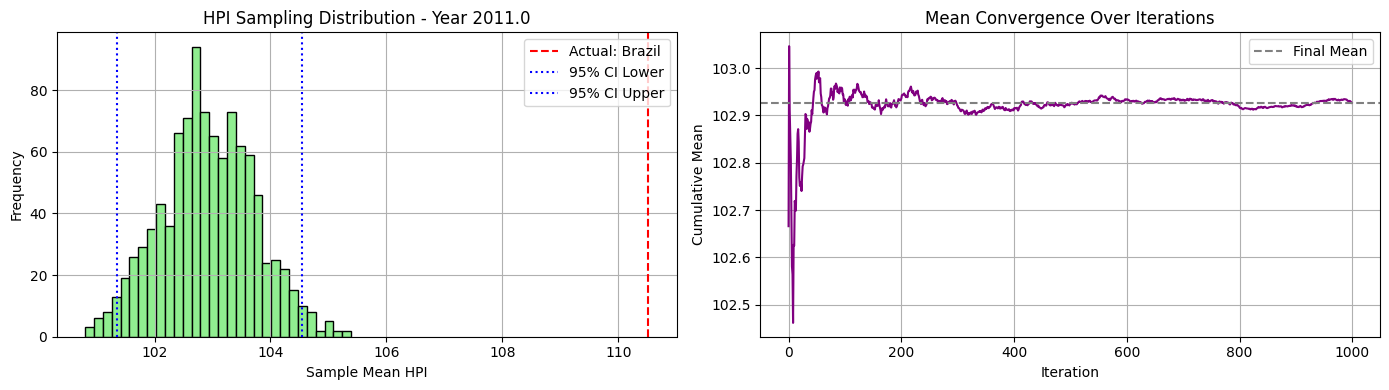


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 110.62 124.02 118.79  98.56  95.67 105.11 105.48  92.98 112.38
 124.02  99.19 109.17 115.34 114.94  96.58  91.1   95.68 108.41 108.25
 103.86 107.63 120.68  98.92 101.82]


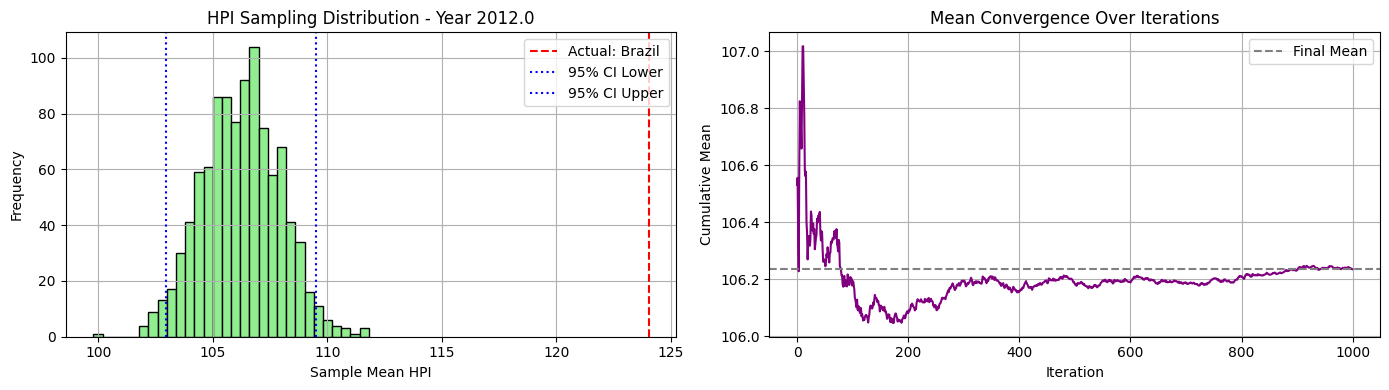


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 112.76 136.52 130.06  98.58  99.37 103.13 108.68  90.58 119.18
 136.52 100.81 114.75 119.98 127.86  92.35  94.32  90.62 115.41 107.8
 109.22 115.99 134.46 101.46 111.83]


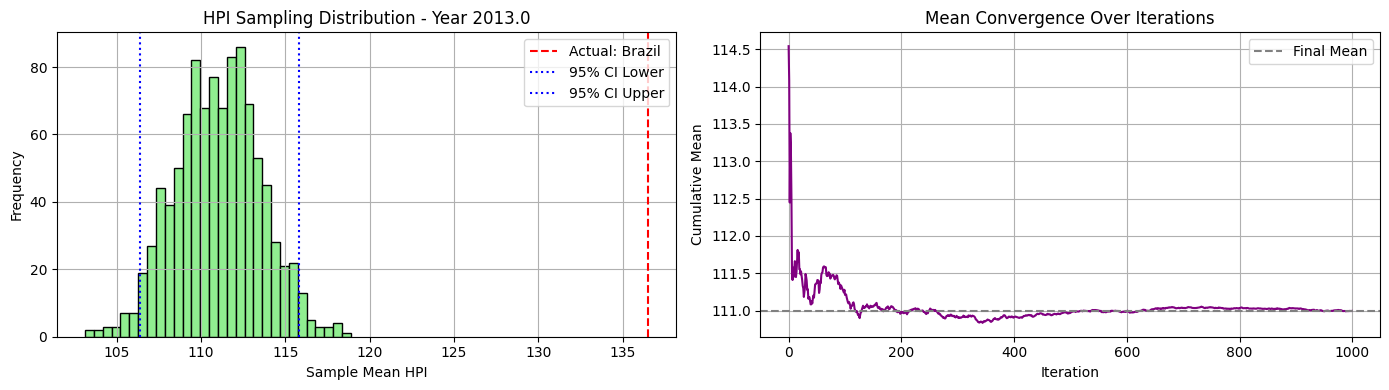


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 118.86 151.67 140.75 101.   103.12 101.58 111.85  94.37 128.94
 151.67 102.38 119.64 123.24 142.76  93.27  95.84  95.77 123.99 109.43
 119.52 127.07 151.25 109.6  118.88]


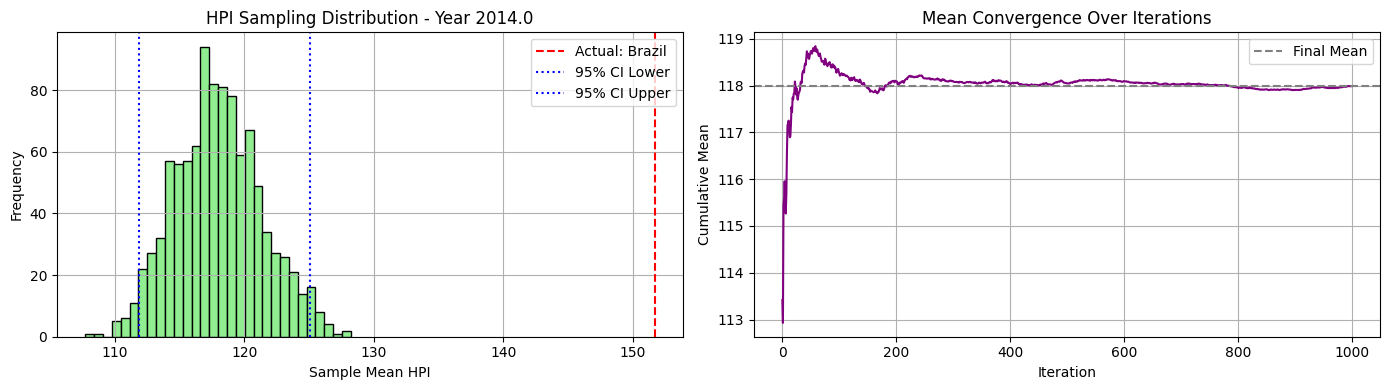


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 128.43 162.89 152.93 105.01 110.29 100.22 117.12 106.75 139.74
 162.89 104.86 129.39 130.76 157.04  94.69  97.    99.5  131.8  113.08
 135.2  136.   162.89 116.12 125.18]


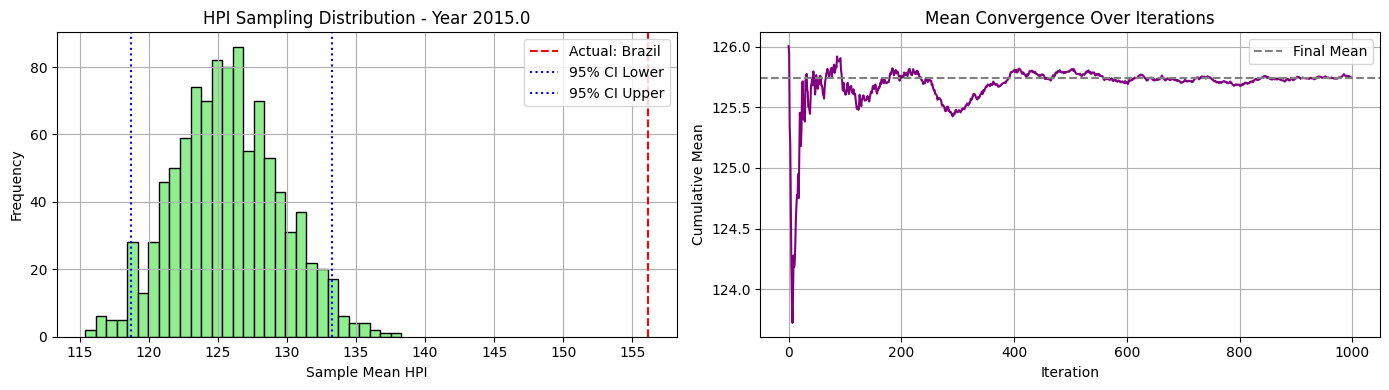


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 148.66 172.75 167.48 112.52 115.5  101.25 125.93 121.03 154.59
 172.75 107.18 138.82 139.95 172.75  96.44  91.86 110.62 138.22 116.09
 146.34 142.4  172.75 124.27 131.88]


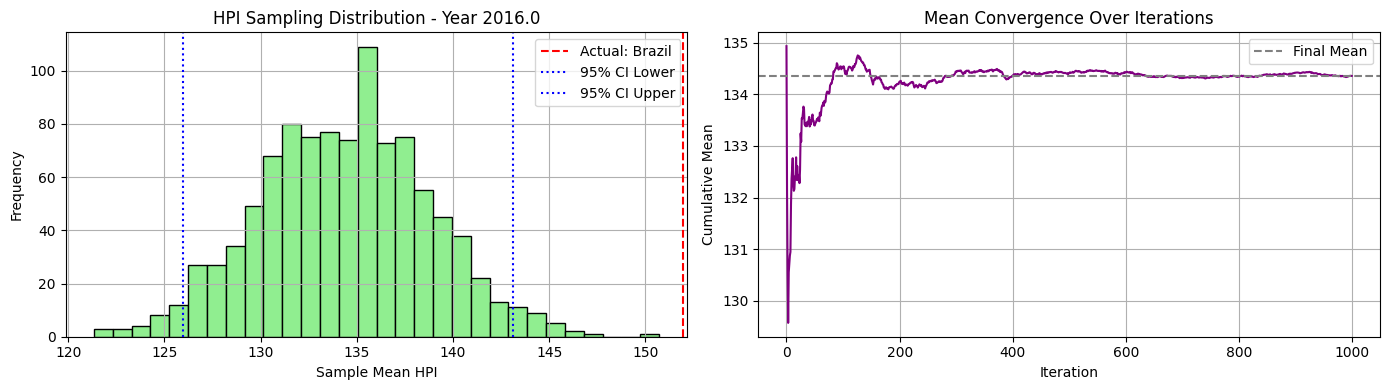


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 172.3  183.99 178.56 125.7  120.63 104.46 133.62 135.84 183.99
 183.99 109.91 149.69 146.91 178.82 100.16  88.54 115.3  143.94 117.6
 156.06 146.48 183.99 129.93 139.61]


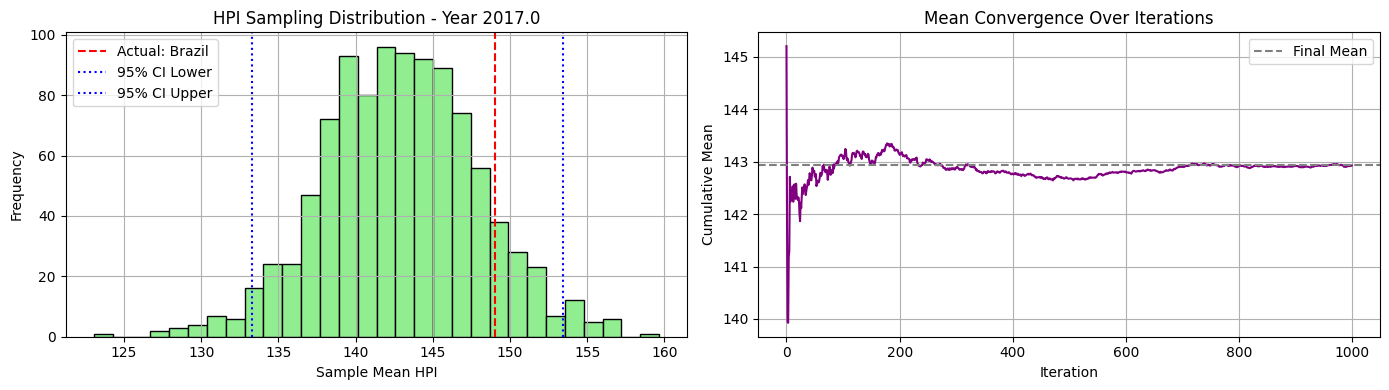


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  178.24 191.85 188.24 136.52 126.31 107.52 142.52 155.3  191.85
 191.85 112.04 162.97 149.04 183.82 106.75  90.72 123.06 148.96 120.22
 154.6  153.9  191.85 134.04 147.35]


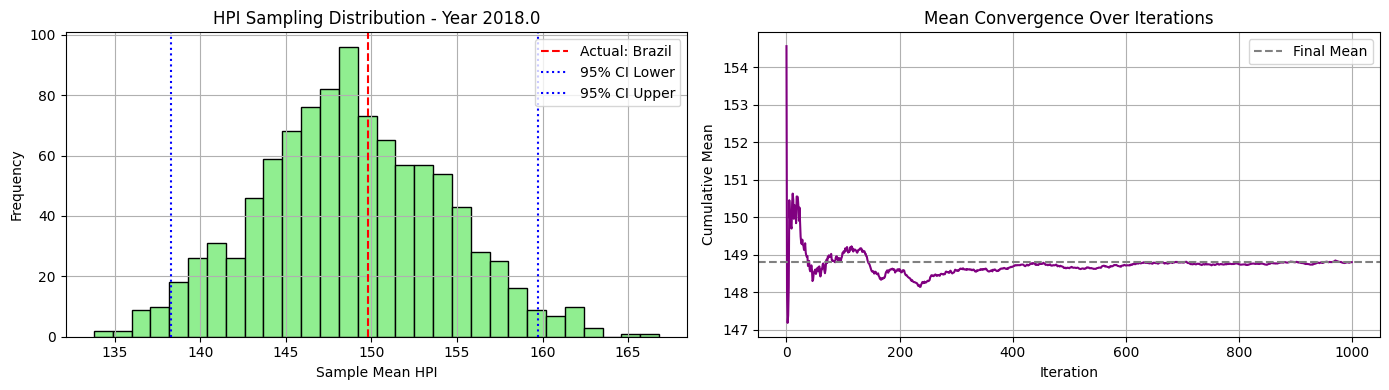


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 179.4  198.37 198.37 149.02 129.62 111.1  150.75 181.64 198.37
 198.37 113.84 176.92 152.73 195.26 116.01  97.25 135.77 152.69 121.93
 158.44 155.1  198.37 135.37 153.14]


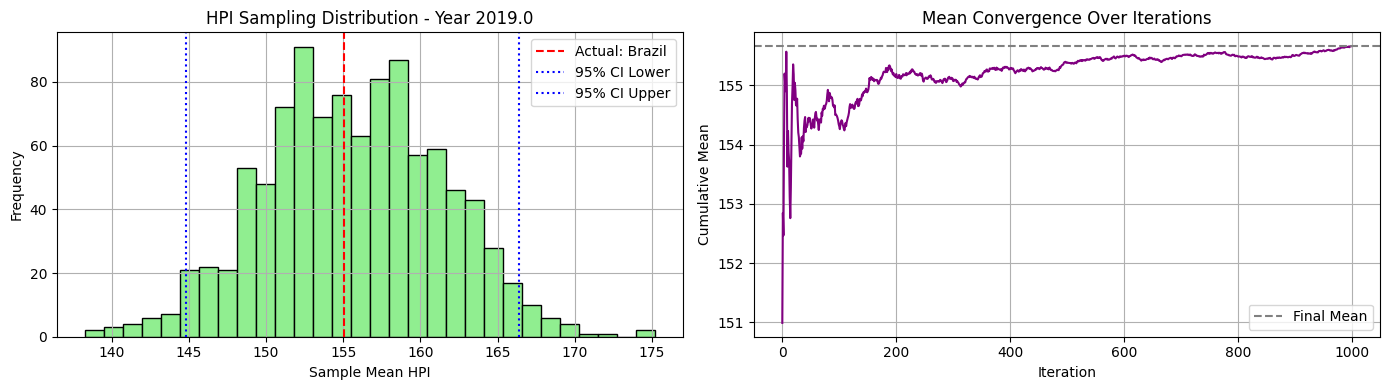


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 190.73 213.74 203.12 161.56 136.24 116.89 162.48 190.63 213.74
 213.74 113.93 187.18 159.24 213.74 128.18 106.71 149.28 156.31 126.56
 165.09 160.6  213.74 139.24 163.52]


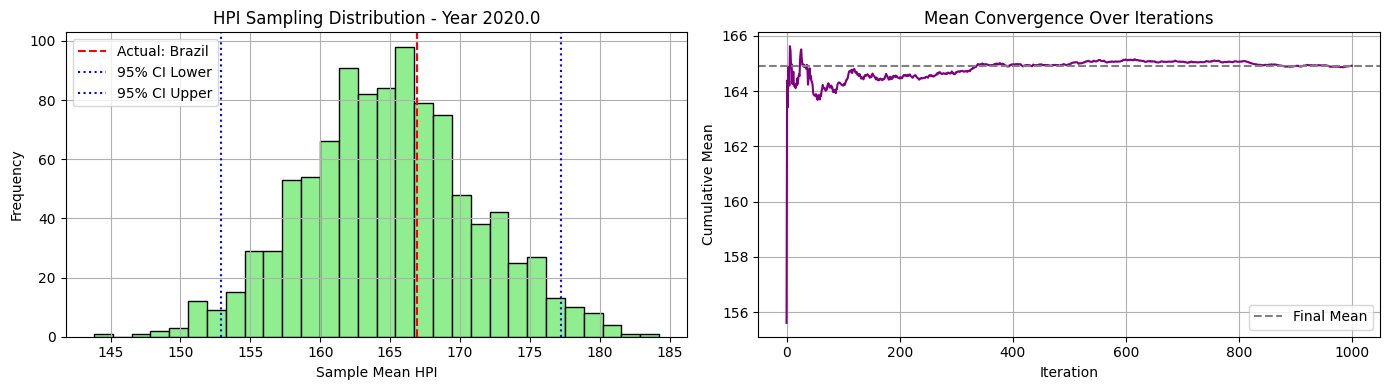


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 214.88 248.26 214.9  193.46 152.2  124.38 181.28 222.1  248.26
 248.26 120.7  201.94 175.91 211.74 139.92 121.41 166.04 166.82 143.73
 181.79 164.23 248.26 150.58 188.56]


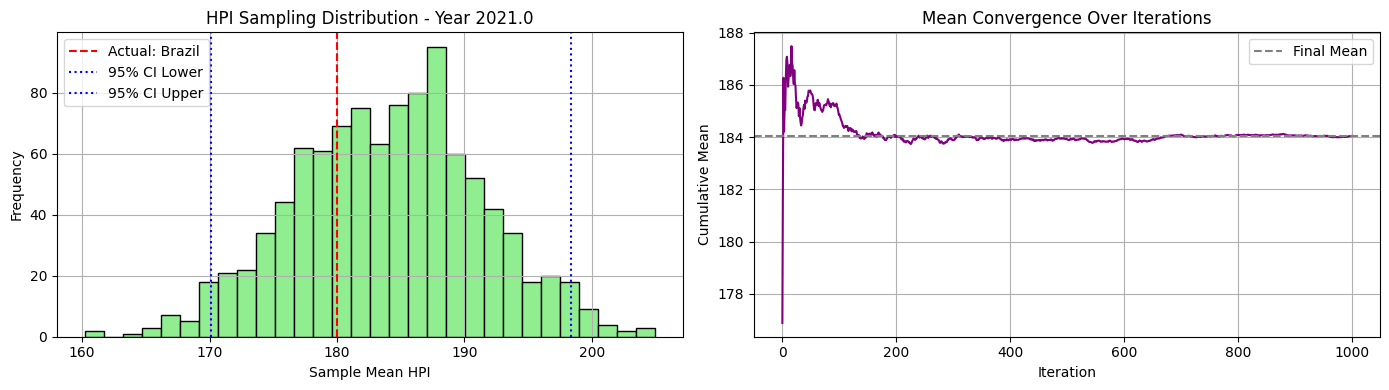


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 235.32 292.18 230.   226.15 151.49 132.1  190.42 271.5  292.18
 292.18 130.84 219.93 185.13 223.73 156.43 155.16 191.49 174.03 153.22
 188.27 169.16 292.18 164.55 213.  ]


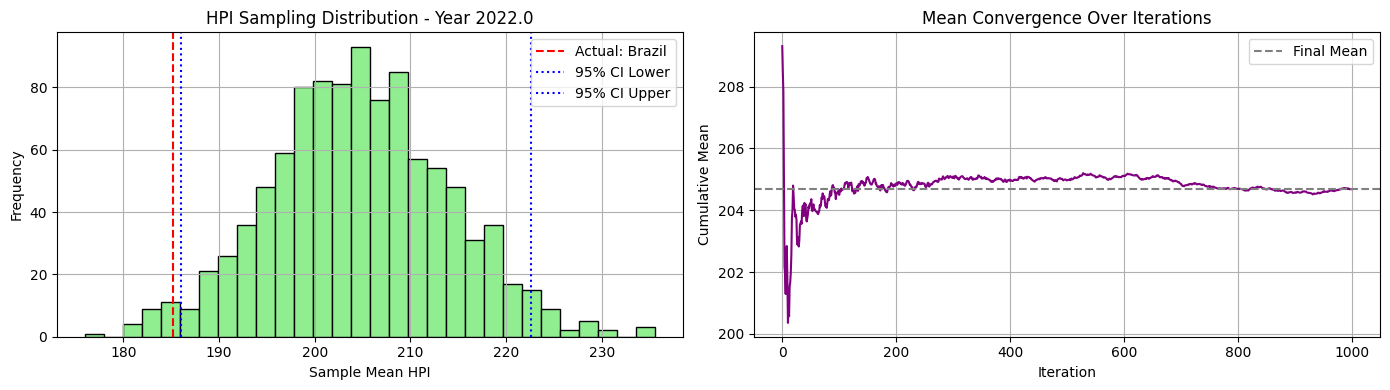


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 221.05 309.37 245.75 222.4  151.24 131.52 174.25 290.98 309.37
 309.37 134.8  243.89 184.12 248.04 170.23 157.88 209.99 176.62 143.99
 178.36 174.79 309.37 165.   221.72]


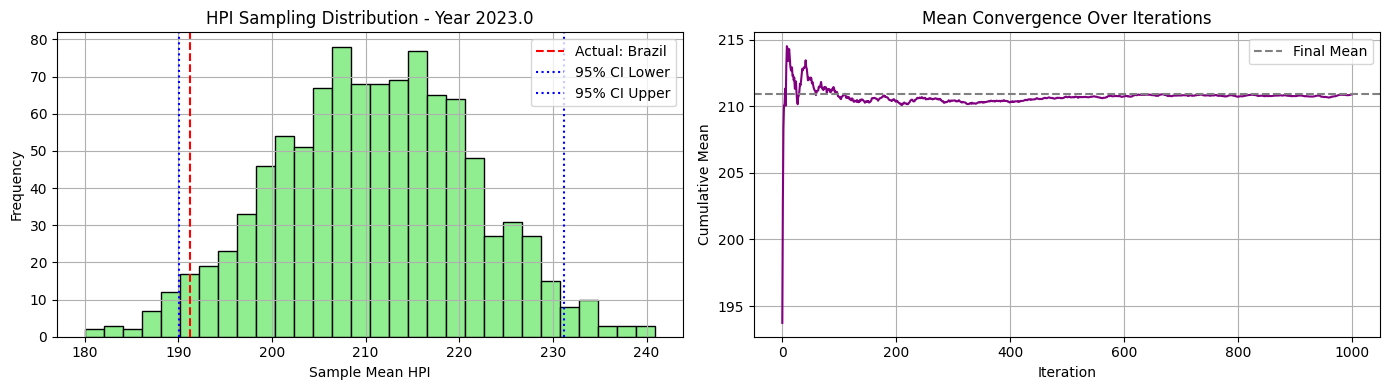


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 217.35 328.24 269.02 233.42 156.73 126.68 171.5  328.1  328.24
 328.24 138.61 266.38 189.05 256.03 195.72 186.66 220.7  178.1  142.46
 178.49 178.06 328.24 166.38 231.23]


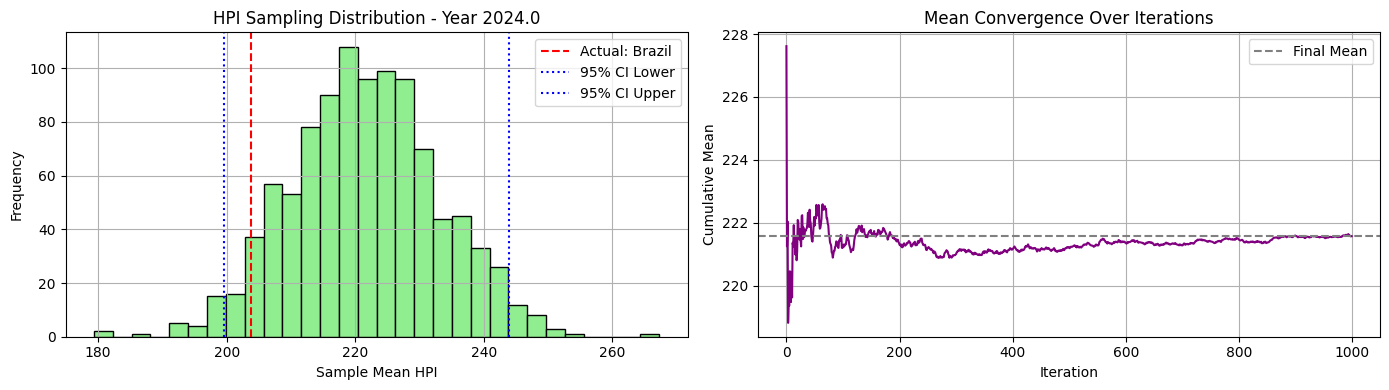

In [11]:
synthetic_c2_ni20_maxi500_h2_46_00, excluded_c2_ni20_maxi500_h2_46_00, actual_c2_ni20_maxi500_h2_46_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=0, seed=43)

🔍 Cluster 1 selected. Excluding country: Belgium
📊 Sampling from countries: ['Austria', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New Zealand', 'Peru', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


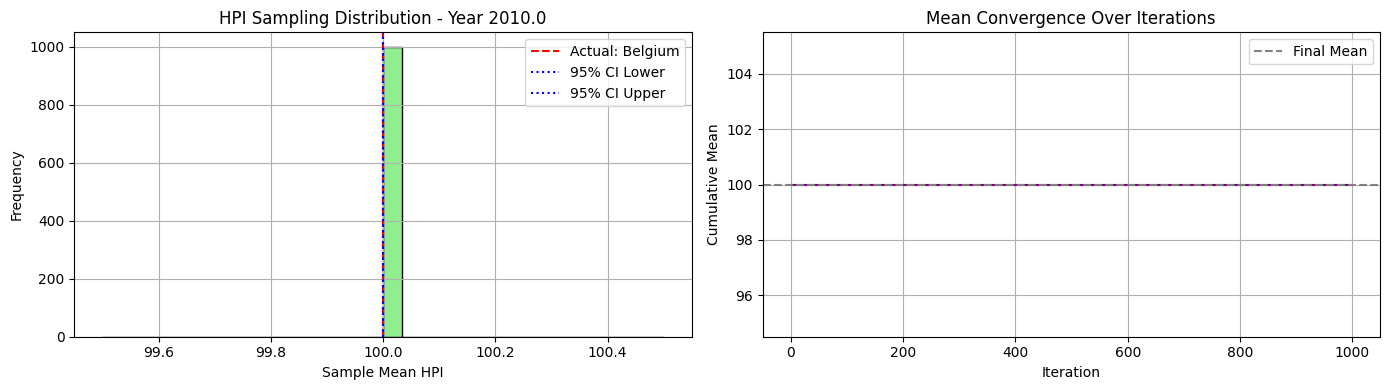


📅 Year 2011.0 - Available HPI values for sampling:
[104.22  94.49 100.16  96.68 108.47 103.17  94.53  94.49 110.52 101.36
 110.42 106.6  103.68 109.83  98.63  98.02 100.75 110.52  95.1   94.49
 109.46  98.46 102.72  94.49 107.51]


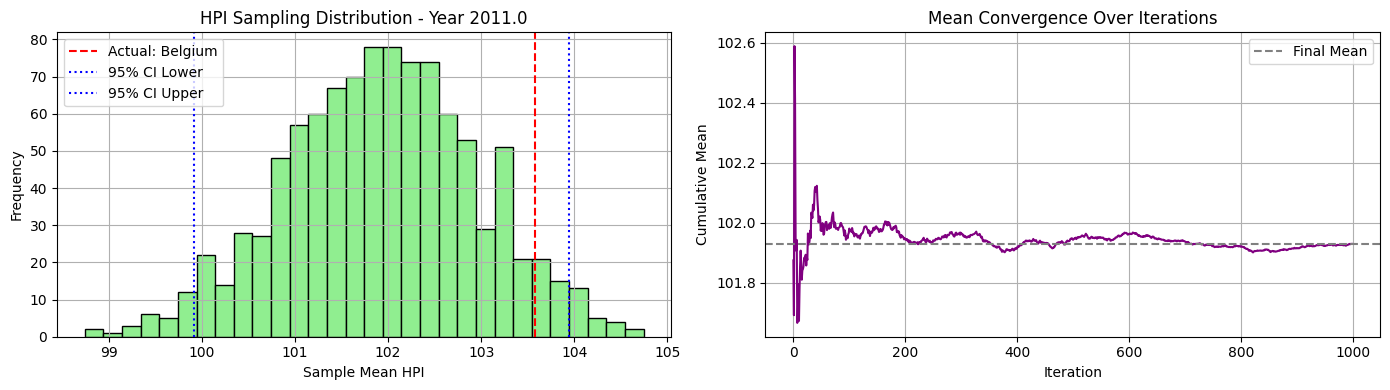


📅 Year 2012.0 - Available HPI values for sampling:
[117.13  92.69  98.62  91.54 116.34 105.64  88.37  88.37 114.1   98.77
 113.71 106.36 108.03 124.02 101.62  91.44 105.25 124.02  88.37  88.37
 112.02  95.73  95.63  88.37 113.72]


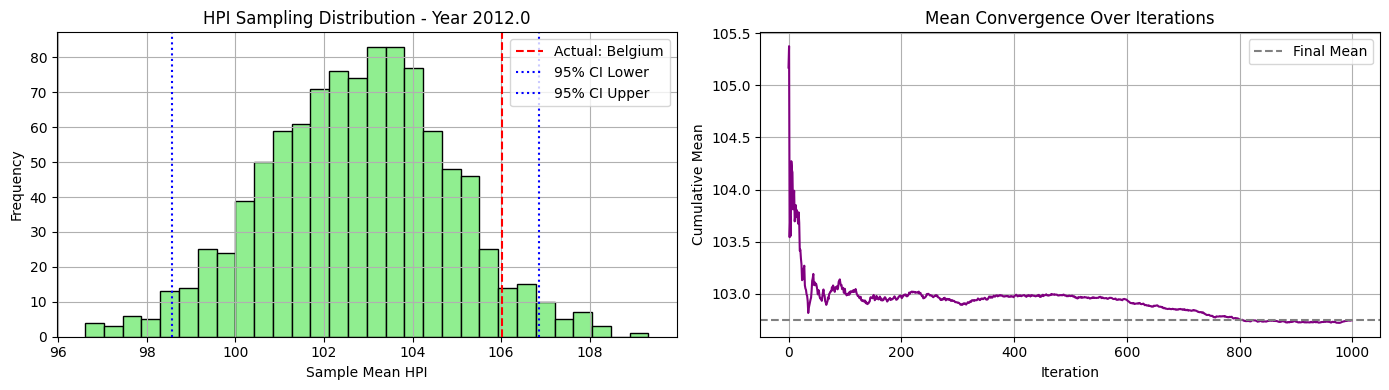


📅 Year 2013.0 - Available HPI values for sampling:
[122.59  90.65  94.7   85.58 128.77 106.87  85.58  85.58 124.45  92.38
 121.5  107.65 113.42 136.52 101.21  85.95 114.59 136.52  86.7   85.58
 115.56  96.53  90.62  85.58 118.3 ]


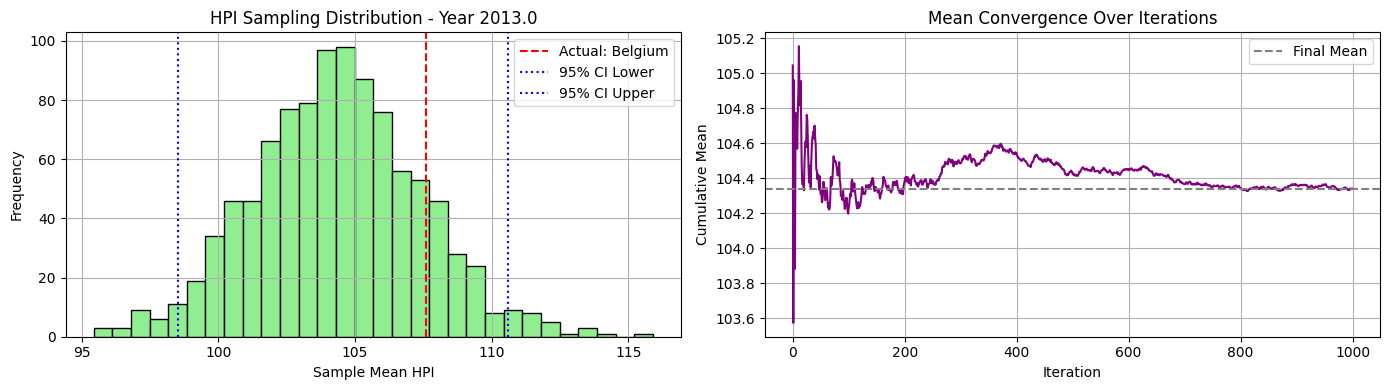


📅 Year 2014.0 - Available HPI values for sampling:
[126.79  91.95  93.19  84.64 146.41 106.5   84.64  84.66 132.36  88.02
 128.78 114.57 118.39 151.67 103.79  86.66 122.03 151.67  90.38  84.64
 112.25  97.8   84.64  84.64 121.46]


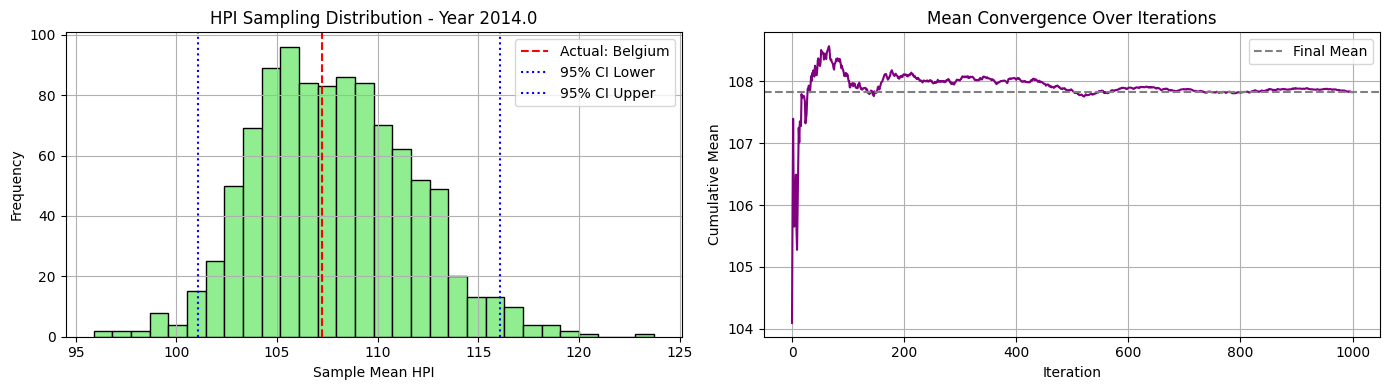


📅 Year 2015.0 - Available HPI values for sampling:
[132.06  94.51  90.54  84.67 156.46 106.5   84.67  94.36 140.12  84.67
 124.46 118.76 124.78 162.89 109.83  89.69 137.18 162.89  93.15  84.67
 107.92 103.    85.32  84.67 124.08]


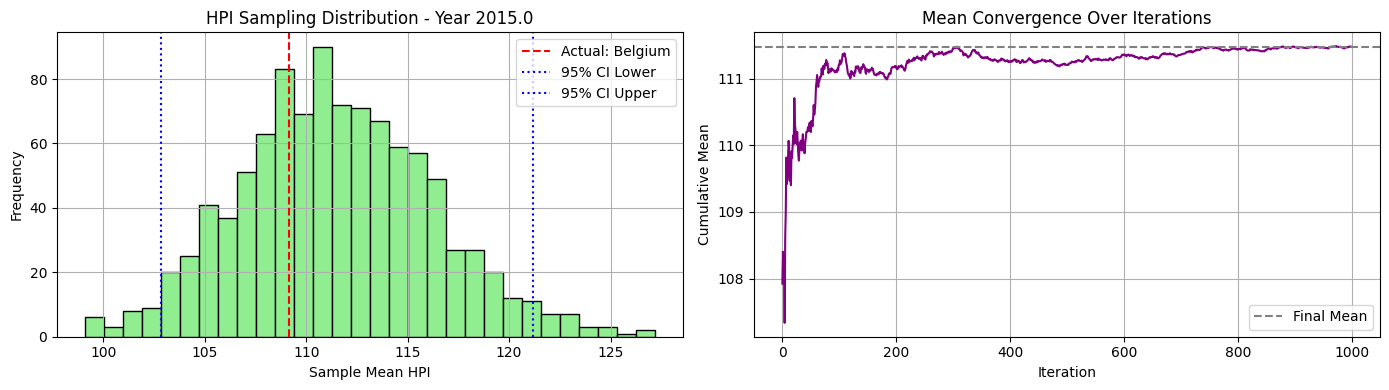


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 101.15  91.33  88.1  163.86 107.86  88.1  101.42 150.56  88.1
 135.02 125.16 132.28 172.75 115.82  94.43 156.62 164.18  99.78  88.91
 104.55 109.87  88.1   88.1  124.32]


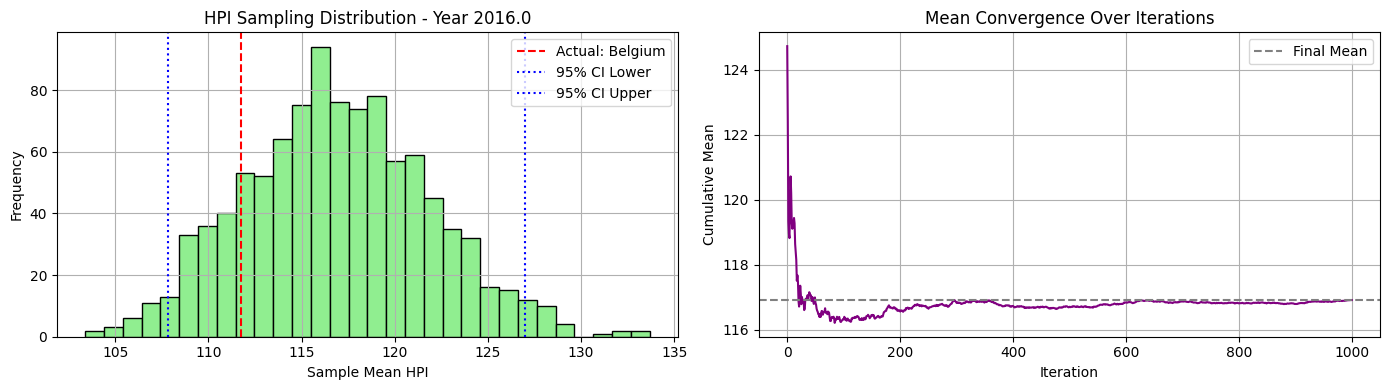


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 109.91  94.84  88.54 172.91 109.02  88.54 112.44 156.44  88.54
 146.87 136.34 139.69 183.99 121.94 102.06 166.8  168.   108.99  93.93
 103.4  116.3   95.38  88.54 125.42]


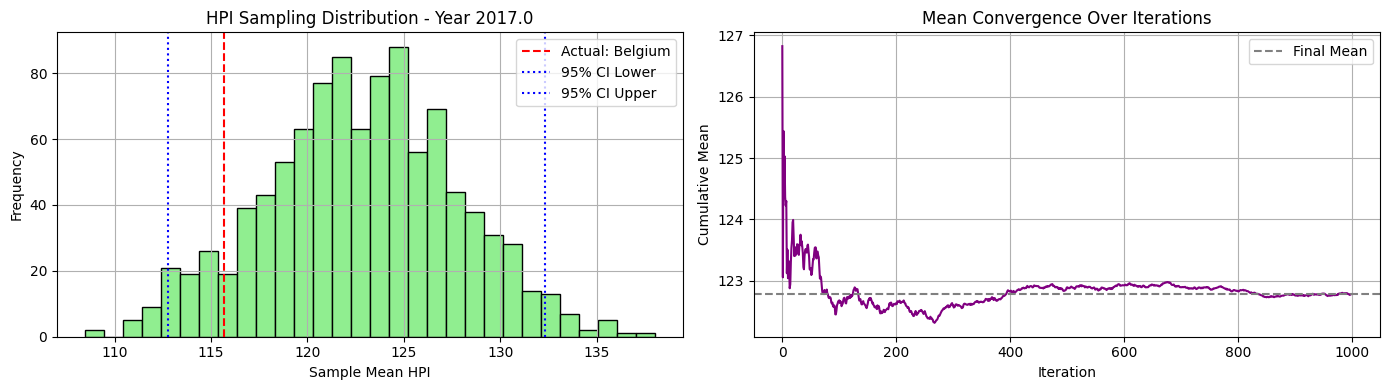


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 117.15 100.59  90.72 183.13 110.06  90.72 123.96 155.14  90.72
 160.92 146.29 149.55 191.85 129.02 111.57 172.8  168.42 120.19  99.37
 111.46 124.97 103.7   90.72 129.16]


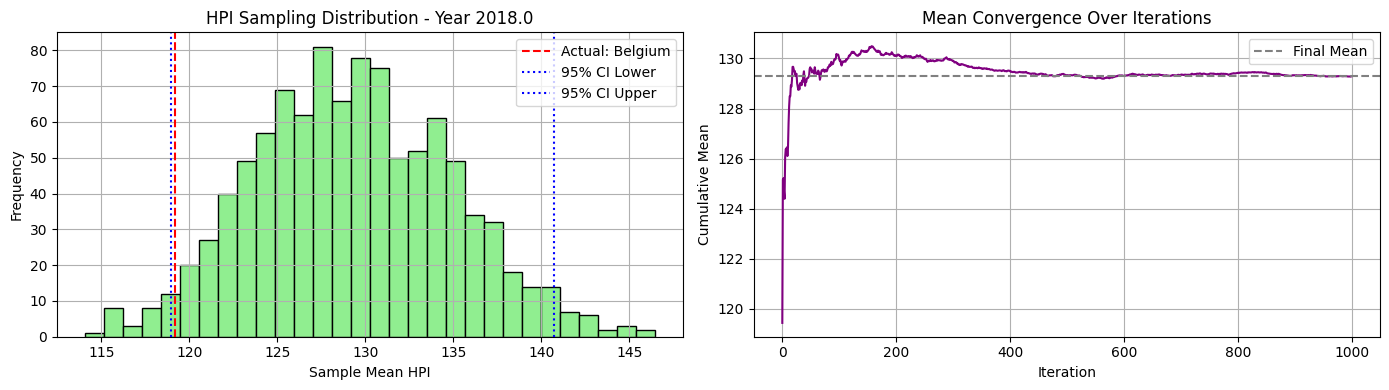


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 124.2  109.64  97.25 195.98 110.52  97.25 126.85 158.06  97.25
 175.33 156.3  164.68 196.06 136.9  119.62 178.19 172.03 132.16 102.72
 113.98 136.39 110.65  97.25 133.99]


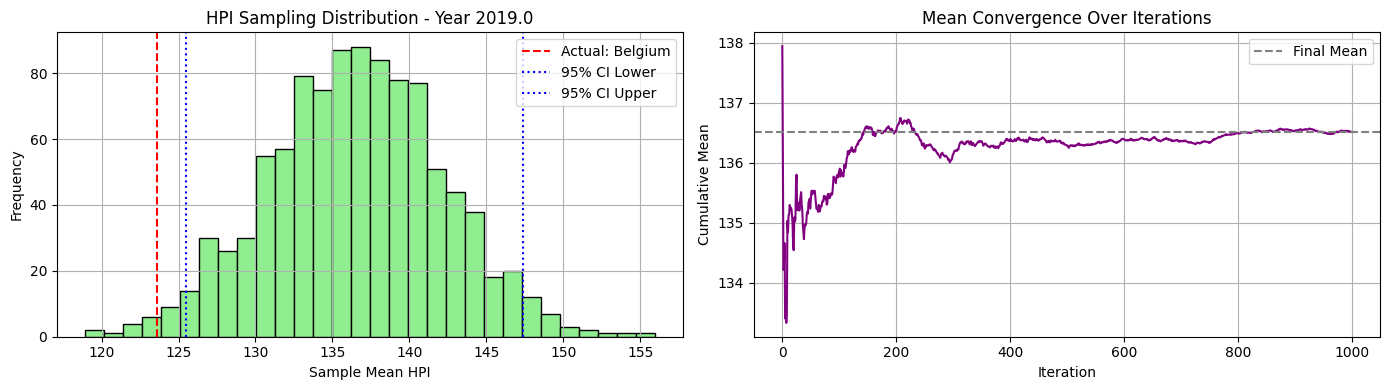


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 129.87 118.06 106.71 207.78 112.49 106.71 127.24 162.9  106.71
 181.42 167.66 188.57 198.37 141.54 129.21 196.31 173.67 143.75 107.53
 115.8  149.36 115.74 106.71 137.31]


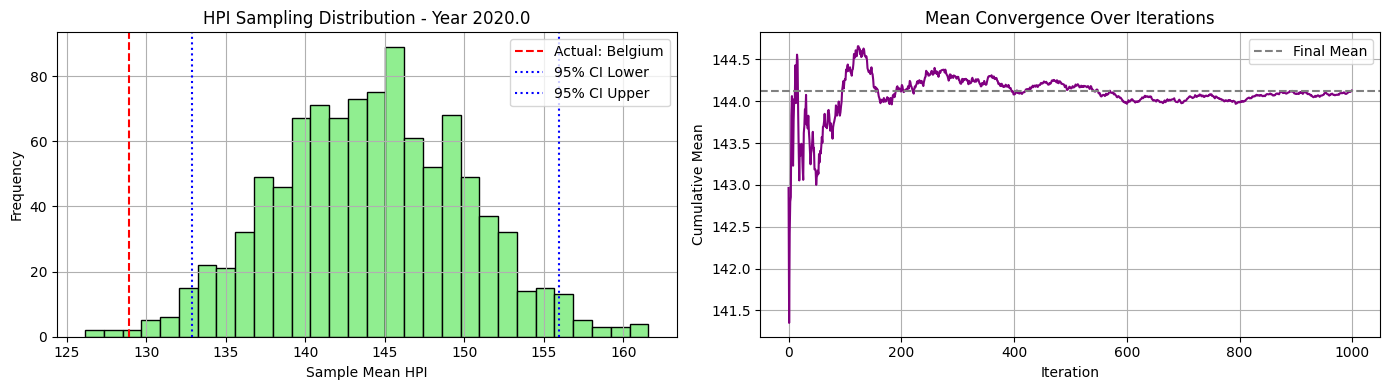


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 141.14 126.64 112.34 239.04 117.62 112.34 137.77 176.65 112.34
 201.18 194.58 214.81 200.69 148.74 147.93 248.26 173.6  157.27 112.34
 125.04 158.94 129.1  112.34 145.16]


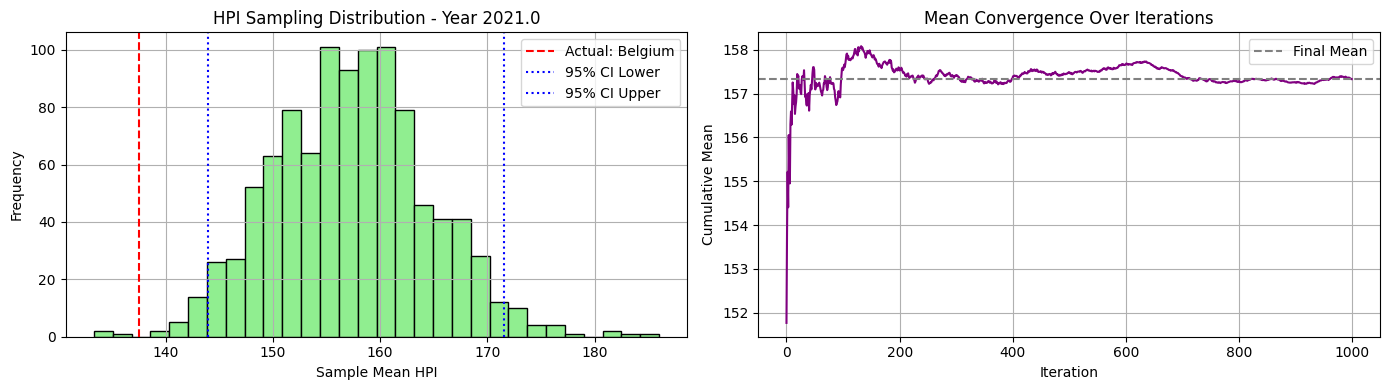


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 160.59 145.44 118.98 292.18 118.98 118.98 154.73 207.16 118.98
 229.01 231.64 235.34 207.75 158.62 167.57 249.69 172.65 177.14 120.29
 137.74 180.7  148.16 118.98 154.42]


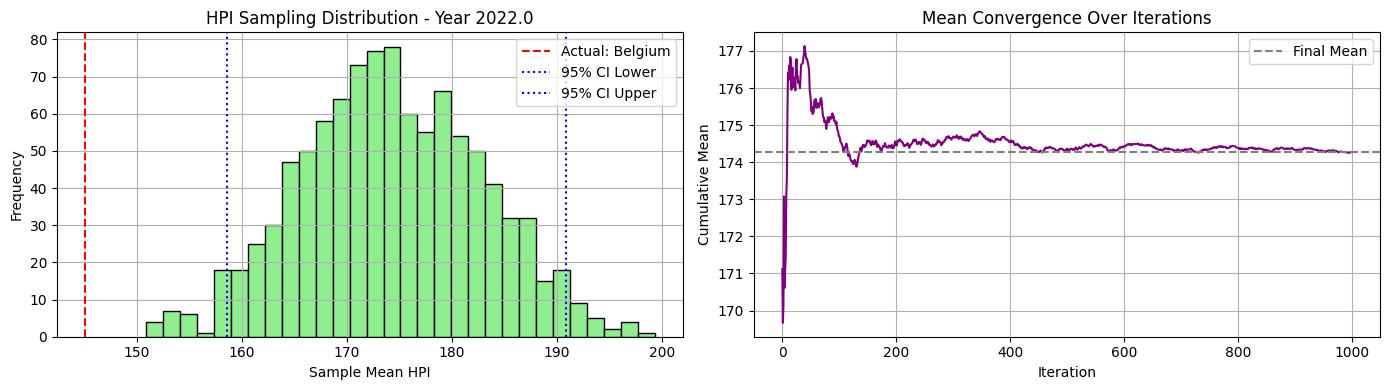


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 176.43 162.82 112.27 309.37 112.27 112.27 159.48 214.23 112.27
 237.56 254.38 214.   216.19 168.5  164.36 233.54 175.16 191.66 124.06
 148.01 180.36 158.88 112.27 157.81]


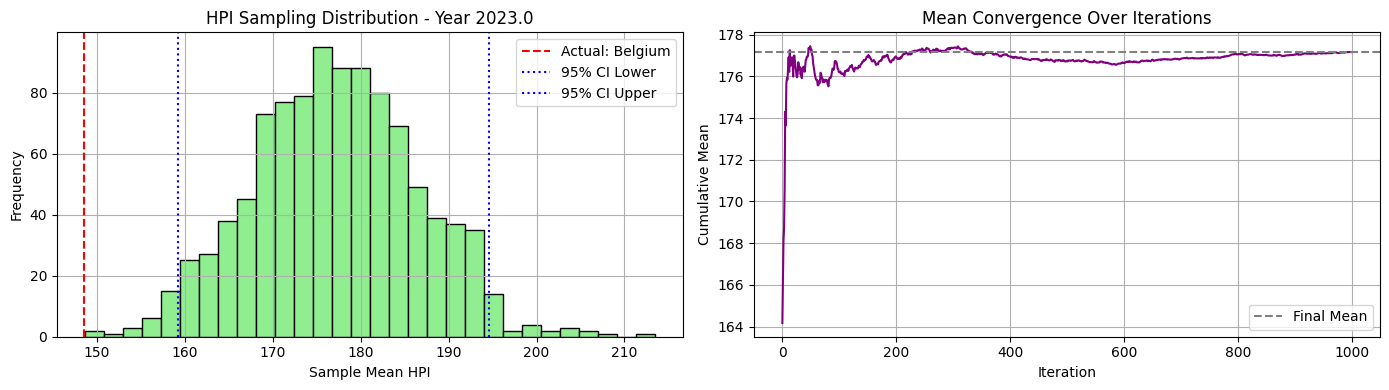


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 205.53 179.7  119.1  328.24 119.1  119.1  173.07 224.54 119.1
 247.54 279.12 202.74 225.06 179.35 177.7  233.68 175.38 209.06 130.34
 155.12 187.15 170.56 119.1  160.56]


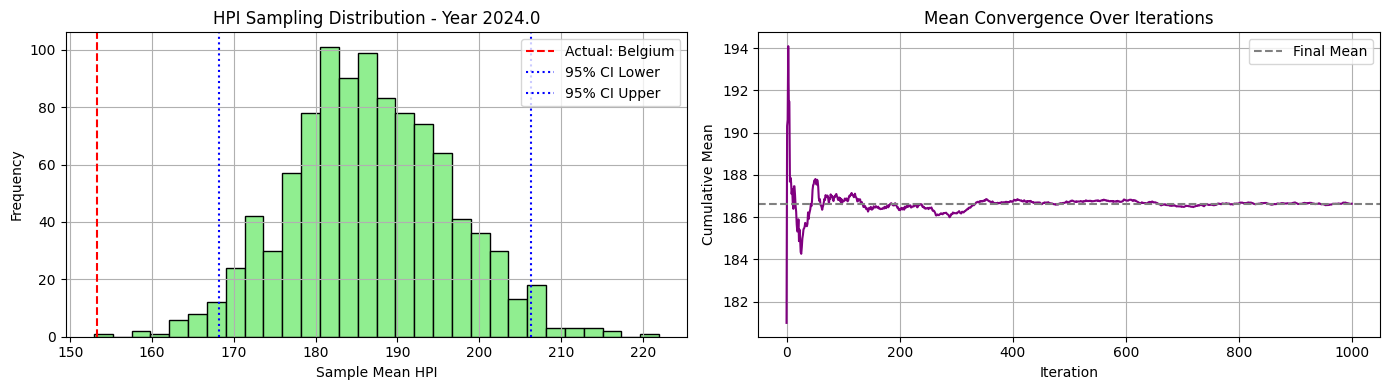

In [12]:
synthetic_c2_ni20_maxi500_h2_46_01, excluded_c2_ni20_maxi500_h2_46_01, actual_c2_ni20_maxi500_h2_46_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=1, seed=43)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [14]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [15]:
import re

def evaluate_all_seeds(synthetic_groups, actual_groups):
    """
    Evaluates multiple sets of synthetic vs. actual HPI dictionaries,
    and stores error metrics in a dictionary keyed by seed number.

    Parameters:
    - synthetic_groups: dict with keys like 'synthetic_42' and values as lists of synthetic dicts
    - actual_groups: dict with keys like 'actual_42' and values as lists of actual dicts

    Returns:
    - metrics_by_seed: dict with seed as key and {'mse': ..., 'mae': ...} as value
    """
    metrics_by_seed = {}

    for synthetic_key in synthetic_groups:
        # Extract seed number from the synthetic key
        match = re.search(r'_(\d+)$', synthetic_key)
        if not match:
            raise ValueError(f"Could not extract seed from key: {synthetic_key}")
        
        seed = int(match.group(1))
        actual_key = f'actual_{seed}'  # construct matching key for actual_groups

        if actual_key not in actual_groups:
            raise KeyError(f"Missing key in actual_groups: {actual_key}")

        synthetic_dicts = synthetic_groups[synthetic_key]
        actual_dicts = actual_groups[actual_key]

        mse, mae = compute_global_mse_mae(synthetic_dicts, actual_dicts)
        metrics_by_seed[seed] = {'mse': mse, 'mae': mae}

    return metrics_by_seed

In [16]:
def summarize_error_metrics(metrics_by_seed):
    """
    Computes the mean and median of MSE and MAE values across multiple seeds.

    Parameters:
    - metrics_by_seed: dictionary with seed as key and {'mse': ..., 'mae': ...} as value

    Returns:
    - summary: dictionary with keys 'mse_mean', 'mse_median', 'mae_mean', 'mae_median'
    """
    mse_values = [metrics['mse'] for metrics in metrics_by_seed.values()]
    mae_values = [metrics['mae'] for metrics in metrics_by_seed.values()]

    summary = {
        'mse_mean': np.mean(mse_values),
        'mse_median': np.median(mse_values),
        'mae_mean': np.mean(mae_values),
        'mae_median': np.median(mae_values)
    }

    return summary

In [17]:
a = [synthetic_c2_ni20_maxi500_h2_23_00, synthetic_c2_ni20_maxi500_h2_23_01]
b = [actual_c2_ni20_maxi500_h2_23_00, actual_c2_ni20_maxi500_h2_23_01]

c = [synthetic_c2_ni20_maxi500_h2_32_00, synthetic_c2_ni20_maxi500_h2_32_01]
d = [actual_c2_ni20_maxi500_h2_32_00, actual_c2_ni20_maxi500_h2_32_01]

e = [synthetic_c2_ni20_maxi500_h2_46_00, synthetic_c2_ni20_maxi500_h2_46_01]
f = [actual_c2_ni20_maxi500_h2_46_00, actual_c2_ni20_maxi500_h2_46_01]

In [18]:
synth_c2_ni20_maxi500_h2 = {
    'synthetic_32': a,
    'synthetic_43': c,
    'synthetic_52': e
}

actual_c2_ni20_maxi500_h2 = {
    'actual_32': b,
    'actual_43': d,
    'actual_52': f
}

In [19]:
results_c2_ni20_maxi500_h2 = evaluate_all_seeds(synth_c2_ni20_maxi500_h2, actual_c2_ni20_maxi500_h2)

In [20]:
for seed, metrics in results_c2_ni20_maxi500_h2.items():
    print(f"🔢 Seed {seed} → MSE: {metrics['mse']:.4f}, MAE: {metrics['mae']:.4f}")

🔢 Seed 32 → MSE: 273.3327, MAE: 12.4674
🔢 Seed 43 → MSE: 280.1628, MAE: 13.3638
🔢 Seed 52 → MSE: 277.1974, MAE: 12.5268


In [21]:
summary_c2_ni20_maxi500_h2 = summarize_error_metrics(results_c2_ni20_maxi500_h2)

In [22]:
print("📈 Error Summary Across Seeds:")
print(f"Mean MSE: {summary_c2_ni20_maxi500_h2['mse_mean']:.4f}")
print(f"Median MSE: {summary_c2_ni20_maxi500_h2['mse_median']:.4f}")
print(f"Mean MAE: {summary_c2_ni20_maxi500_h2['mae_mean']:.4f}")
print(f"Median MAE: {summary_c2_ni20_maxi500_h2['mae_median']:.4f}")

📈 Error Summary Across Seeds:
Mean MSE: 276.8976
Median MSE: 277.1974
Mean MAE: 12.7860
Median MAE: 12.5268


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [34]:
from datetime import datetime

In [35]:
log_df = pd.read_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [36]:
pd.set_option('display.max_columns', None)

In [37]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
21,kmeans_plusplus_c3_ni20_maxi500_no_3_countries...,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,931.318725,23.745640
22,kmeans_plusplus_c2_ni20_maxi500_3_countries_ex...,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.131965,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,873.227083,19.651486
23,kmeans_plusplus_c3_ni20_maxi500_3_countries_ex...,2025-09-14 22:16,"Winsorization, RobustScaler",53,KMeans,3,k-means++,20.0,500.0,42,True,True,1,0.105738,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,1564.283633,27.561166
24,kmeans_plusplus_c2_ni20_maxi500_5_27deleted_wi...,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.408223,"RobustScaler, log transformation",Winsorization x5,True,False,"Winsorization, rounding",Winsorization x2,bootstrap,"[23, 32, 46]",3.0,657.423582,19.836296
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755


In [27]:
h2 = ['gdp', 'inflation_df', 'agr_land', 'livestock_prod']

In [38]:
new_entry_c2_ni20_maxi500_5_win1 = {
    'experiment_name': 'kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_3_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': 0.448165,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'Winsorization',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'bootstrap',
    'mse_score': summary_c2_ni20_maxi500_h2['mse_mean'],
    'mae_score': summary_c2_ni20_maxi500_h2['mae_mean'],
    'sampling_seed': (32,43,52),
    'excluded_countries_count': 3,
    'used_all_variables_for_clustering': h2,
    'used_pca_for_clustering': False,
    "premacroecon_conversion_transform": None,
    "countries_used_for_clustering": 53
}

In [39]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry_c2_ni20_maxi500_5_win1])], ignore_index=True)

In [40]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
22,kmeans_plusplus_c2_ni20_maxi500_3_countries_ex...,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.131965,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,873.227083,19.651486
23,kmeans_plusplus_c3_ni20_maxi500_3_countries_ex...,2025-09-14 22:16,"Winsorization, RobustScaler",53,KMeans,3,k-means++,20.0,500.0,42,True,True,1,0.105738,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,1564.283633,27.561166
24,kmeans_plusplus_c2_ni20_maxi500_5_27deleted_wi...,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.408223,"RobustScaler, log transformation",Winsorization x5,True,False,"Winsorization, rounding",Winsorization x2,bootstrap,"[23, 32, 46]",3.0,657.423582,19.836296
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755
26,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"[gdp, inflation_df, agr_land, livestock_prod]",False,"Winsorization, rounding",Winsorization,bootstrap,"(32, 43, 52)",3.0,276.897625,12.785992


In [41]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [42]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')